In [ ]:

import pandas as pd
import numpy as np
df = pd.read_csv('Cleaned-Dataset.csv')
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("\nCOLUMN NAMES:")
print(df.columns.tolist())
print("\nFIRST FIVE ROWS:")
display(df.head())
print("\nMISSING VALUES:")
missing = df.isnull().sum()
display(missing[missing > 0])
print("\nCOUNTRIES:", df['country_name'].nunique())
print("YEARS:", sorted(df['year'].unique()))
print("\nDUPLICATES:",
      df.duplicated(subset=['country_iso3', 'year']).sum())


Number of rows: 2951
Number of columns: 26

COLUMN NAMES:
['year', 'country_iso3', 'country_name', 'country_id', 'Interest Rate (Real, %)', 'Public Debt (% of GDP)', 'exports_usd', 'imports_usd', 'trade_balance_usd', 'export_partner_hhi', 'export_product_hhi', 'momentum_score', 'risk_score', 'Inflation (CPI %)', 'GDP (Current USD)', 'GDP per Capita (Current USD)', 'Unemployment Rate (%)', 'Inflation (GDP Deflator, %)', 'GDP Growth (% Annual)', 'Current Account Balance (% GDP)', 'Government Expense (% of GDP)', 'Government Revenue (% of GDP)', 'Tax Revenue (% of GDP)', 'Gross National Income (USD)', 'Public Debt (% of GDP)_imputed', 'Interest Rate (Real, %)_imputed']

FIRST FIVE ROWS:


,year,country_iso3,country_name,country_id,"Interest Rate (Real, %)",Public Debt (% of GDP),exports_usd,imports_usd,trade_balance_usd,export_partner_hhi,...,Unemployment Rate (%),"Inflation (GDP Deflator, %)",GDP Growth (% Annual),Current Account Balance (% GDP),Government Expense (% of GDP),Government Revenue (% of GDP),Tax Revenue (% of GDP),Gross National Income (USD),Public Debt (% of GDP)_imputed,"Interest Rate (Real, %)_imputed"
0,2010,ABW,Aruba,aw,11.666131,NaN,3.097702e+08,1.365677e+09,-1.055906e+09,1206.812399,...,6.8110,-1.223407,-2.733457,-18.752537,25.042629,22.796607,15.499091,2.313385e+09,False,False
1,2011,ABW,Aruba,aw,4.801974,NaN,4.159465e+09,3.167220e+09,9.922454e+08,5312.395184,...,6.5310,4.005674,3.369237,-9.877656,24.356611,23.696164,16.004298,2.391841e+09,False,False
2,2012,ABW,Aruba,aw,8.200875,NaN,1.676321e+09,2.460389e+09,-7.840688e+08,2360.915225,...,6.5815,0.184033,-1.040800,3.473451,24.633442,24.608739,15.547482,2.499118e+09,False,False
3,2013,ABW,Aruba,aw,10.709709,NaN,6.906054e+08,3.488950e+09,-2.798345e+09,843.991007,...,6.2905,-1.995948,6.431483,-11.813206,24.601894,24.116817,15.842007,2.563517e+09,False,False
4,2014,ABW,Aruba,aw,3.213869,NaN,6.681904e+08,3.723592e+09,-3.055401e+09,1259.937499,...,6.2655,3.958897,-1.586575,-4.658577,25.417034,24.515167,15.976303,2.688102e+09,False,False



MISSING VALUES:


,0
"Interest Rate (Real, %)",1238
Public Debt (% of GDP),2107
momentum_score,6



COUNTRIES: 197
YEARS: [np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]

DUPLICATES: 0


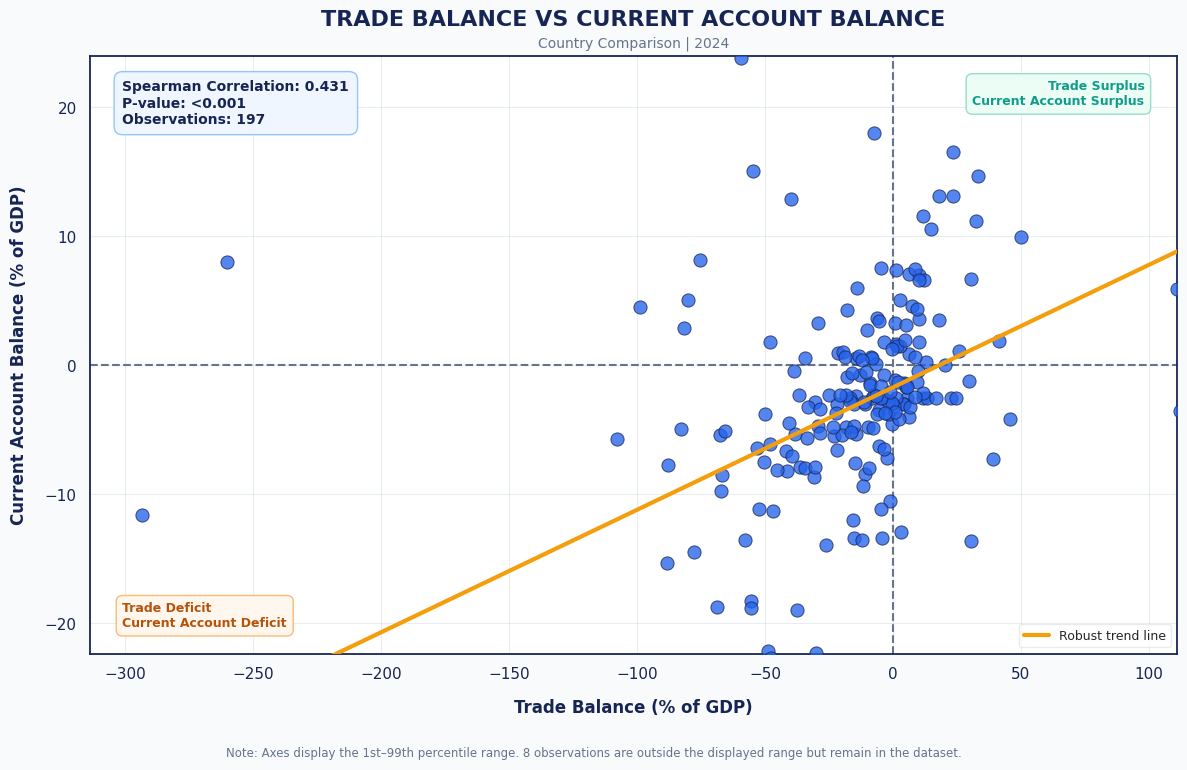

TRADE BALANCE VS CURRENT ACCOUNT BALANCE
Year: 2024
Valid observations: 197
Spearman correlation: 0.4314
P-value: 2.4668378664416677e-10
Theil-Sen slope: 0.0949
Observations outside displayed limits: 8


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from scipy.stats import spearmanr, theilslopes

df = pd.read_csv("Cleaned-Dataset.csv")

NAVY = "#172554"
BLUE = "#2563EB"
TEAL = "#0F9D8A"
ORANGE = "#F59E0B"
GREY = "#64748B"
LIGHT_GREY = "#E2E8F0"
BACKGROUND = "#F8FAFC"

required = [
    "year", "GDP (Current USD)", "trade_balance_usd",
    "Current Account Balance (% GDP)"
]

missing = [col for col in required if col not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

for col in required:
    df[col] = pd.to_numeric(df[col], errors="coerce")

data = df[
    (df["year"] == 2024) &
    (df["GDP (Current USD)"] > 0)
].copy()

data["Trade Balance % GDP"] = (
    data["trade_balance_usd"] / data["GDP (Current USD)"] * 100
)

data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=[
    "Trade Balance % GDP",
    "Current Account Balance (% GDP)"
])

if len(data) < 3:
    raise ValueError("Not enough valid observations.")

x = data["Trade Balance % GDP"]
y = data["Current Account Balance (% GDP)"]

rho, p_value = spearmanr(x, y)
slope, intercept, _, _ = theilslopes(y, x)

x_low, x_high = x.quantile([0.01, 0.99])
y_low, y_high = y.quantile([0.01, 0.99])

outside = (
    (x < x_low) | (x > x_high) |
    (y < y_low) | (y > y_high)
)

outlier_count = int(outside.sum())

if x_low == x_high:
    x_low, x_high = x.min(), x.max()
if y_low == y_high:
    y_low, y_high = y.min(), y.max()

if x_low == x_high:
    x_low -= 1
    x_high += 1
if y_low == y_high:
    y_low -= 1
    y_high += 1

sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.labelweight": "semibold",
    "figure.facecolor": BACKGROUND,
    "axes.facecolor": "white",
    "axes.edgecolor": NAVY,
    "axes.linewidth": 1.3,
    "grid.color": LIGHT_GREY,
    "grid.linewidth": 0.8,
    "xtick.color": NAVY,
    "ytick.color": NAVY
})

fig, ax = plt.subplots(figsize=(12, 8))

sns.scatterplot(
    data=data,
    x="Trade Balance % GDP",
    y="Current Account Balance (% GDP)",
    color=BLUE,
    s=90,
    alpha=0.78,
    edgecolor=NAVY,
    linewidth=0.7,
    ax=ax,
    zorder=3
)

x_line = np.linspace(x_low, x_high, 200)
ax.plot(
    x_line,
    slope * x_line + intercept,
    color=ORANGE,
    linewidth=3,
    label="Robust trend line",
    zorder=4
)

ax.axhline(0, color=GREY, linestyle="--", linewidth=1.5)
ax.axvline(0, color=GREY, linestyle="--", linewidth=1.5)

ax.set_xlim(x_low, x_high)
ax.set_ylim(y_low, y_high)

if x_low < 0 < x_high and y_low < 0 < y_high:
    ax.text(
        0.97, 0.96,
        "Trade Surplus\nCurrent Account Surplus",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9,
        color=TEAL,
        weight="bold",
        bbox=dict(
            boxstyle="round,pad=0.5",
            facecolor="#ECFDF5",
            edgecolor="#99DCCB"
        )
    )

    ax.text(
        0.03, 0.04,
        "Trade Deficit\nCurrent Account Deficit",
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=9,
        color="#B45309",
        weight="bold",
        bbox=dict(
            boxstyle="round,pad=0.5",
            facecolor="#FFF7ED",
            edgecolor="#FDBA74"
        )
    )

ax.set_title(
    "TRADE BALANCE VS CURRENT ACCOUNT BALANCE",
    color=NAVY,
    fontsize=16,
    fontweight="bold",
    pad=22
)

ax.text(
    0.5, 1.015,
    "Country Comparison | 2024",
    transform=ax.transAxes,
    ha="center",
    color=GREY,
    fontsize=10
)

ax.set_xlabel("Trade Balance (% of GDP)", color=NAVY, labelpad=12)
ax.set_ylabel("Current Account Balance (% of GDP)", color=NAVY, labelpad=12)

p_text = "<0.001" if p_value < 0.001 else f"{p_value:.3f}"

ax.text(
    0.03, 0.96,
    f"Spearman Correlation: {rho:.3f}\n"
    f"P-value: {p_text}\n"
    f"Observations: {len(data)}",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=10,
    color=NAVY,
    fontweight="semibold",
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor="#EFF6FF",
        edgecolor="#93C5FD"
    )
)

ax.legend(
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor=LIGHT_GREY,
    fontsize=9
)

ax.grid(True, linestyle="-", alpha=0.75)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color(NAVY)
    spine.set_linewidth(1.3)

fig.text(
    0.5, 0.015,
    f"Note: Axes display the 1st–99th percentile range. "
    f"{outlier_count} observations are outside the displayed range "
    "but remain in the dataset.",
    ha="center",
    fontsize=8.5,
    color=GREY
)

plt.tight_layout(rect=[0, 0.045, 1, 0.97])

plt.savefig(
    "Plot_6_Improved.png",
    dpi=350,
    bbox_inches="tight",
    facecolor=BACKGROUND
)

plt.show()

print("TRADE BALANCE VS CURRENT ACCOUNT BALANCE")
print("Year: 2024")
print("Valid observations:", len(data))
print("Spearman correlation:", round(rho, 4))
print("P-value:", p_value)
print("Theil-Sen slope:", round(slope, 4))
print("Observations outside displayed limits:", outlier_count)

files.download("Plot_6_Improved.png")


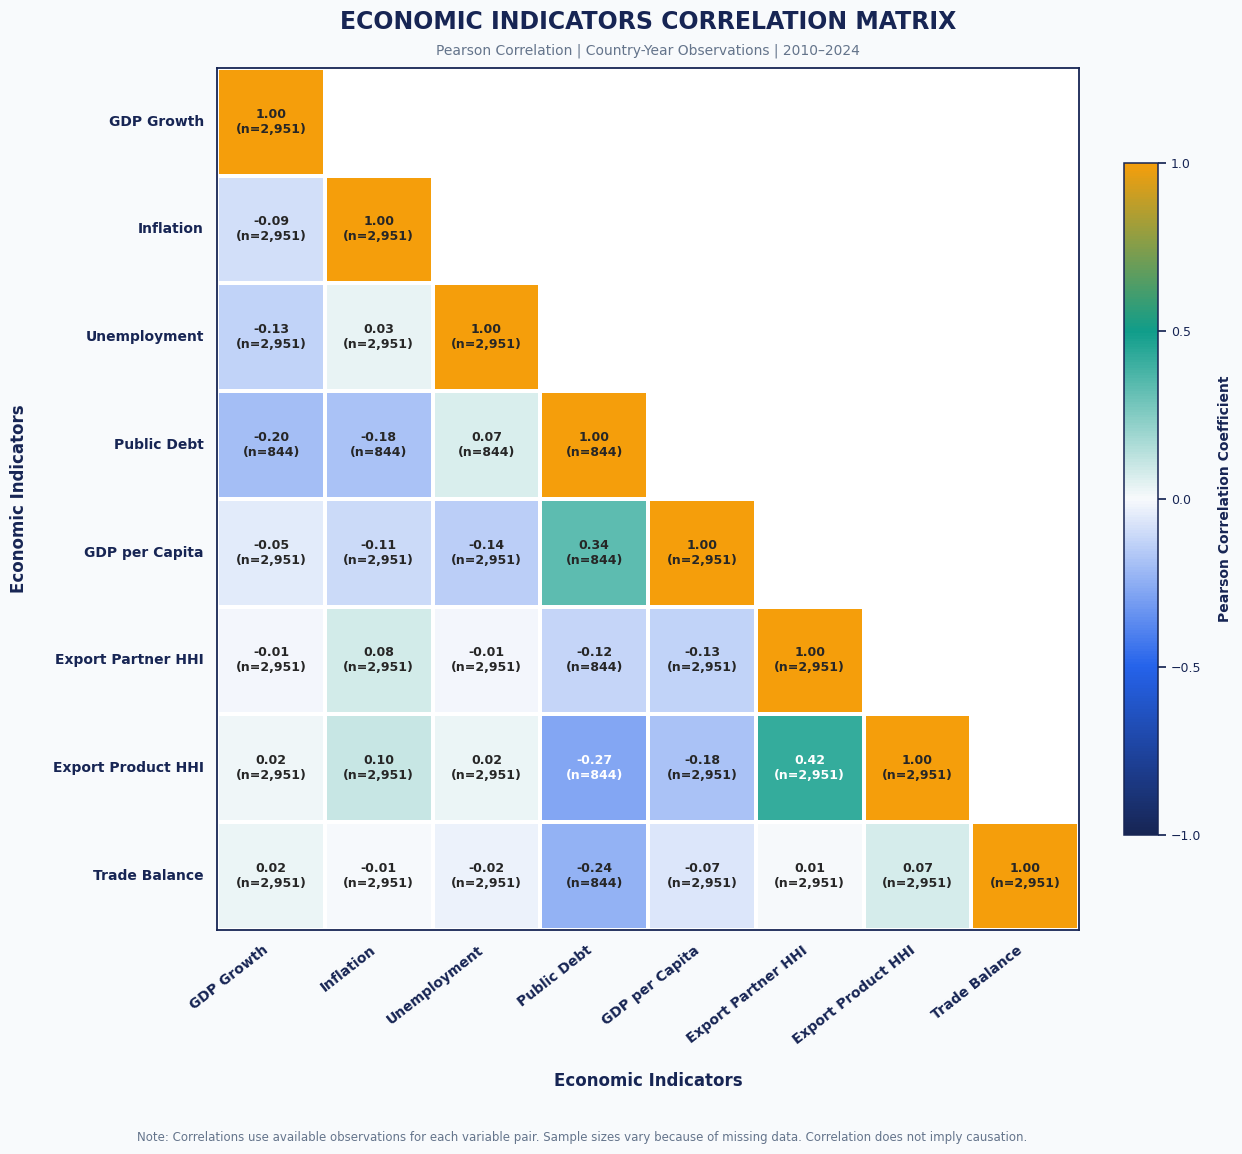

ECONOMIC INDICATORS CORRELATION RESULTS

Correlation Matrix:
                     GDP Growth  Inflation  Unemployment  Public Debt  \
GDP Growth               1.000     -0.087        -0.126       -0.201   
Inflation               -0.087      1.000         0.034       -0.182   
Unemployment            -0.126      0.034         1.000        0.070   
Public Debt             -0.201     -0.182         0.070        1.000   
GDP per Capita          -0.053     -0.107        -0.141        0.335   
Export Partner HHI      -0.011      0.081        -0.011       -0.123   
Export Product HHI       0.017      0.102         0.024       -0.275   
Trade Balance            0.024     -0.008        -0.024       -0.239   

                    GDP per Capita  Export Partner HHI  Export Product HHI  \
GDP Growth                  -0.053              -0.011               0.017   
Inflation                   -0.107               0.081               0.102   
Unemployment                -0.141              -0.011 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from matplotlib.colors import LinearSegmentedColormap
NAVY = "#172554"
BLUE = "#2563EB"
TEAL = "#0F9D8A"
ORANGE = "#F59E0B"
GREY = "#64748B"
BACKGROUND = "#F8FAFC"

economic_cmap = LinearSegmentedColormap.from_list(
    "Economic_Correlation", [NAVY, BLUE, BACKGROUND, TEAL, ORANGE], N=256
)

columns = {
    "GDP Growth (% Annual)": "GDP Growth",
    "Inflation (CPI %)": "Inflation",
    "Unemployment Rate (%)": "Unemployment",
    "Public Debt (% of GDP)": "Public Debt",
    "GDP per Capita (Current USD)": "GDP per Capita",
    "export_partner_hhi": "Export Partner HHI",
    "export_product_hhi": "Export Product HHI",
    "trade_balance_usd": "Trade Balance"
}

missing = [col for col in columns if col not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

plot_data = df[list(columns)].apply(pd.to_numeric, errors="coerce")
plot_data = plot_data.replace([np.inf, -np.inf], np.nan).rename(columns=columns)

correlation = plot_data.corr(method="pearson", min_periods=3)
sample_sizes = plot_data.notna().astype(int).T.dot(plot_data.notna().astype(int))

annotation = pd.DataFrame("", index=correlation.index, columns=correlation.columns)

for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):
        r = correlation.iloc[i, j]
        n = sample_sizes.iloc[i, j]
        if j <= i:
            annotation.iloc[i, j] = f"{r:.2f}\n(n={n:,})" if pd.notna(r) else f"N/A\n(n={n:,})"

mask = np.triu(np.ones(correlation.shape, dtype=bool), k=1)

sns.set_theme(style="white", context="notebook")
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.titlesize": 17, "axes.titleweight": "bold",
    "figure.facecolor": BACKGROUND, "axes.facecolor": "white",
    "text.color": NAVY, "xtick.color": NAVY, "ytick.color": NAVY
})

fig, ax = plt.subplots(figsize=(15, 12))
fig.patch.set_facecolor(BACKGROUND)

heatmap = sns.heatmap(
    correlation, mask=mask, annot=annotation.values, fmt="",
    cmap=economic_cmap, center=0, vmin=-1, vmax=1, square=True,
    linewidths=1.5, linecolor="white",
    annot_kws={"size": 9, "weight": "semibold"},
    cbar_kws={"shrink": 0.78, "pad": 0.035, "ticks": [-1, -0.5, 0, 0.5, 1]},
    ax=ax
)

ax.set_title("ECONOMIC INDICATORS CORRELATION MATRIX", fontsize=17, fontweight="bold", color=NAVY, pad=28)

ax.text(
    0.5, 1.015, "Pearson Correlation | Country-Year Observations | 2010–2024",
    transform=ax.transAxes, ha="center", fontsize=10, color=GREY
)

ax.set_xlabel("Economic Indicators", fontsize=12, fontweight="bold", color=NAVY, labelpad=18)
ax.set_ylabel("Economic Indicators", fontsize=12, fontweight="bold", color=NAVY, labelpad=18)

plt.xticks(rotation=38, ha="right", fontsize=10, fontweight="semibold")
plt.yticks(rotation=0, fontsize=10, fontweight="semibold")

colorbar = heatmap.collections[0].colorbar
colorbar.ax.tick_params(labelsize=9, colors=NAVY)
colorbar.set_label("Pearson Correlation Coefficient", fontsize=10, fontweight="bold", color=NAVY, labelpad=12)
colorbar.outline.set_edgecolor(NAVY)
colorbar.outline.set_linewidth(1.1)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color(NAVY)
    spine.set_linewidth(1.3)

fig.text(
    0.5, 0.015,
    "Note: Correlations use available observations for each variable pair. "
    "Sample sizes vary because of missing data. Correlation does not imply causation.",
    ha="center", fontsize=8.5, color=GREY
)

plt.tight_layout(rect=[0, 0.045, 1, 0.97])
plt.savefig("Plot_18_Improved.png", dpi=350, bbox_inches="tight", facecolor=BACKGROUND)
plt.show()

upper = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool))
strongest = upper.stack().rename("Correlation").reset_index()
strongest.columns = ["Variable 1", "Variable 2", "Correlation"]
strongest["Absolute Correlation"] = strongest["Correlation"].abs()
strongest = strongest.sort_values("Absolute Correlation", ascending=False)

print("ECONOMIC INDICATORS CORRELATION RESULTS")
print("\nCorrelation Matrix:\n", correlation.round(3))
print("\nPairwise Sample Sizes:\n", sample_sizes)
print("\nMissing Observations:\n", plot_data.isnull().sum())
print("\nStrongest Economic Relationships:\n", strongest.head(10)[["Variable 1", "Variable 2", "Correlation"]].to_string(index=False))

files.download("Plot_18_Improved.png")


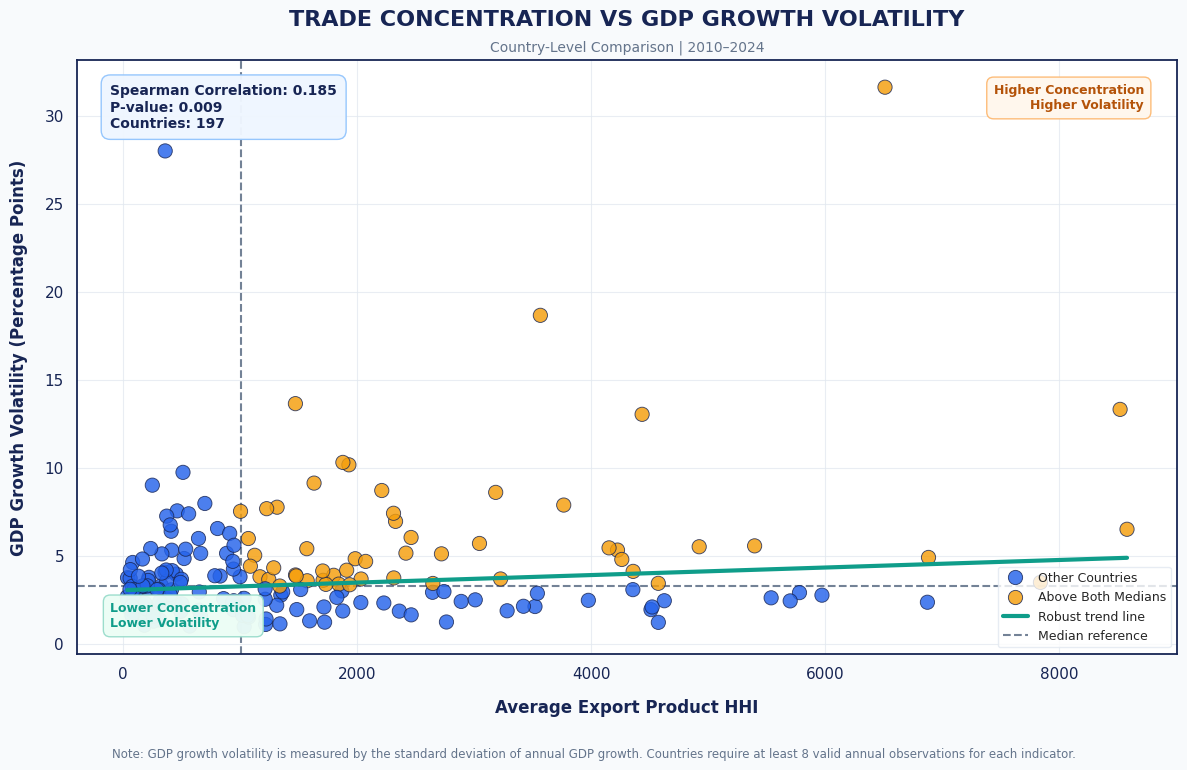

TRADE CONCENTRATION VS GDP GROWTH VOLATILITY
Study period: 2010–2024
Countries included: 197
Spearman correlation: 0.1849
P-value: 0.009287250265391898
Theil-Sen slope: 0.000214
Median Product HHI: 1003.12
Median GDP Volatility: 3.2703
Countries above both medians: 54

COUNTRIES WITH THE HIGHEST GDP VOLATILITY:
            country_name  Product_HHI  GDP_Volatility  GDP_Years  HHI_Years
                   Libya  6512.193143       31.616567         15         15
        Macao SAR, China   359.113549       27.997415         15         15
                  Guyana  3566.161835       18.661364         15         15
                Maldives  1472.205788       13.645996         15         15
             South Sudan  8521.840303       13.320364         13         13
             Timor-Leste  4435.860609       13.039849         15         15
Central African Republic  1878.006912       10.309281         15         15
                   Aruba  1929.545717       10.172008         15         15
   

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from scipy.stats import spearmanr, theilslopes
NAVY = "#172554"
BLUE = "#2563EB"
TEAL = "#0F9D8A"
ORANGE = "#F59E0B"
GREY = "#64748B"
LIGHT_GREY = "#E2E8F0"
BACKGROUND = "#F8FAFC"

required = ["country_name", "year", "GDP Growth (% Annual)", "export_product_hhi"]
missing = [col for col in required if col not in df.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

for col in ["year", "GDP Growth (% Annual)", "export_product_hhi"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.replace([np.inf, -np.inf], np.nan)
df = df[df["year"].between(2010, 2024)].copy()

MIN_VALID_YEARS = 8

data = df.groupby("country_name").agg(
    GDP_Volatility=("GDP Growth (% Annual)", "std"),
    Product_HHI=("export_product_hhi", "mean"),
    GDP_Years=("GDP Growth (% Annual)", "count"),
    HHI_Years=("export_product_hhi", "count")
).reset_index()

data = data[
    (data["GDP_Years"] >= MIN_VALID_YEARS) &
    (data["HHI_Years"] >= MIN_VALID_YEARS)
].dropna(subset=["GDP_Volatility", "Product_HHI"]).copy()

if len(data) < 3:
    raise ValueError("Not enough countries with sufficient valid observations.")

x = data["Product_HHI"]
y = data["GDP_Volatility"]

rho, p_value = spearmanr(x, y)
slope, intercept, _, _ = theilslopes(y, x)

median_hhi = x.median()
median_volatility = y.median()

data["Economic Group"] = np.where(
    (data["Product_HHI"] >= median_hhi) & (data["GDP_Volatility"] >= median_volatility),
    "Above Both Medians", "Other Countries"
)

sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.titlesize": 16, "axes.titleweight": "bold",
    "axes.labelsize": 12, "axes.labelweight": "semibold",
    "figure.facecolor": BACKGROUND, "axes.facecolor": "white",
    "axes.edgecolor": NAVY, "axes.linewidth": 1.3,
    "grid.color": LIGHT_GREY, "grid.linewidth": 0.8,
    "xtick.color": NAVY, "ytick.color": NAVY
})

fig, ax = plt.subplots(figsize=(12, 8))
fig.patch.set_facecolor(BACKGROUND)

sns.scatterplot(
    data=data, x="Product_HHI", y="GDP_Volatility",
    hue="Economic Group",
    palette={"Other Countries": BLUE, "Above Both Medians": ORANGE},
    s=105, alpha=0.82, edgecolor=NAVY, linewidth=0.65, ax=ax, zorder=3
)

x_line = np.linspace(x.min(), x.max(), 200)
ax.plot(x_line, slope * x_line + intercept, color=TEAL, linewidth=3, label="Robust trend line", zorder=4)

ax.axvline(median_hhi, color=GREY, linestyle="--", linewidth=1.5, alpha=0.9, label="Median reference")
ax.axhline(median_volatility, color=GREY, linestyle="--", linewidth=1.5, alpha=0.9)

ax.text(
    0.97, 0.96, "Higher Concentration\nHigher Volatility",
    transform=ax.transAxes, ha="right", va="top", fontsize=9,
    color="#B45309", weight="bold",
    bbox=dict(boxstyle="round,pad=0.55", facecolor="#FFF7ED", edgecolor="#FDBA74", alpha=0.96)
)

ax.text(
    0.03, 0.04, "Lower Concentration\nLower Volatility",
    transform=ax.transAxes, ha="left", va="bottom", fontsize=9,
    color=TEAL, weight="bold",
    bbox=dict(boxstyle="round,pad=0.55", facecolor="#ECFDF5", edgecolor="#99DCCB", alpha=0.96)
)

p_text = "<0.001" if p_value < 0.001 else f"{p_value:.3f}"

ax.text(
    0.03, 0.96,
    f"Spearman Correlation: {rho:.3f}\nP-value: {p_text}\nCountries: {len(data)}",
    transform=ax.transAxes, ha="left", va="top", fontsize=10,
    color=NAVY, weight="semibold",
    bbox=dict(boxstyle="round,pad=0.65", facecolor="#EFF6FF", edgecolor="#93C5FD", alpha=0.97)
)

ax.set_title("TRADE CONCENTRATION VS GDP GROWTH VOLATILITY", color=NAVY, fontsize=16, fontweight="bold", pad=25)

ax.text(
    0.5, 1.015, "Country-Level Comparison | 2010–2024",
    transform=ax.transAxes, ha="center", color=GREY, fontsize=10
)

ax.set_xlabel("Average Export Product HHI", color=NAVY, labelpad=12)
ax.set_ylabel("GDP Growth Volatility (Percentage Points)", color=NAVY, labelpad=12)

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, labels, loc="lower right", frameon=True, facecolor="white", edgecolor=LIGHT_GREY, fontsize=9)

ax.grid(True, linestyle="-", alpha=0.75)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color(NAVY)
    spine.set_linewidth(1.3)

fig.text(
    0.5, 0.015,
    f"Note: GDP growth volatility is measured by the standard deviation of annual GDP growth. "
    f"Countries require at least {MIN_VALID_YEARS} valid annual observations for each indicator.",
    ha="center", fontsize=8.5, color=GREY
)

plt.tight_layout(rect=[0, 0.045, 1, 0.97])
plt.savefig("Plot_19_Improved.png", dpi=350, bbox_inches="tight", facecolor=BACKGROUND)
plt.show()

print("TRADE CONCENTRATION VS GDP GROWTH VOLATILITY")
print("Study period: 2010–2024")
print("Countries included:", len(data))
print("Spearman correlation:", round(rho, 4))
print("P-value:", p_value)
print("Theil-Sen slope:", round(slope, 6))
print("Median Product HHI:", round(median_hhi, 2))
print("Median GDP Volatility:", round(median_volatility, 4))
print("Countries above both medians:", (data["Economic Group"] == "Above Both Medians").sum())

print("\nCOUNTRIES WITH THE HIGHEST GDP VOLATILITY:")
print(data.nlargest(10, "GDP_Volatility")[["country_name", "Product_HHI", "GDP_Volatility", "GDP_Years", "HHI_Years"]].to_string(index=False))

files.download("Plot_19_Improved.png")


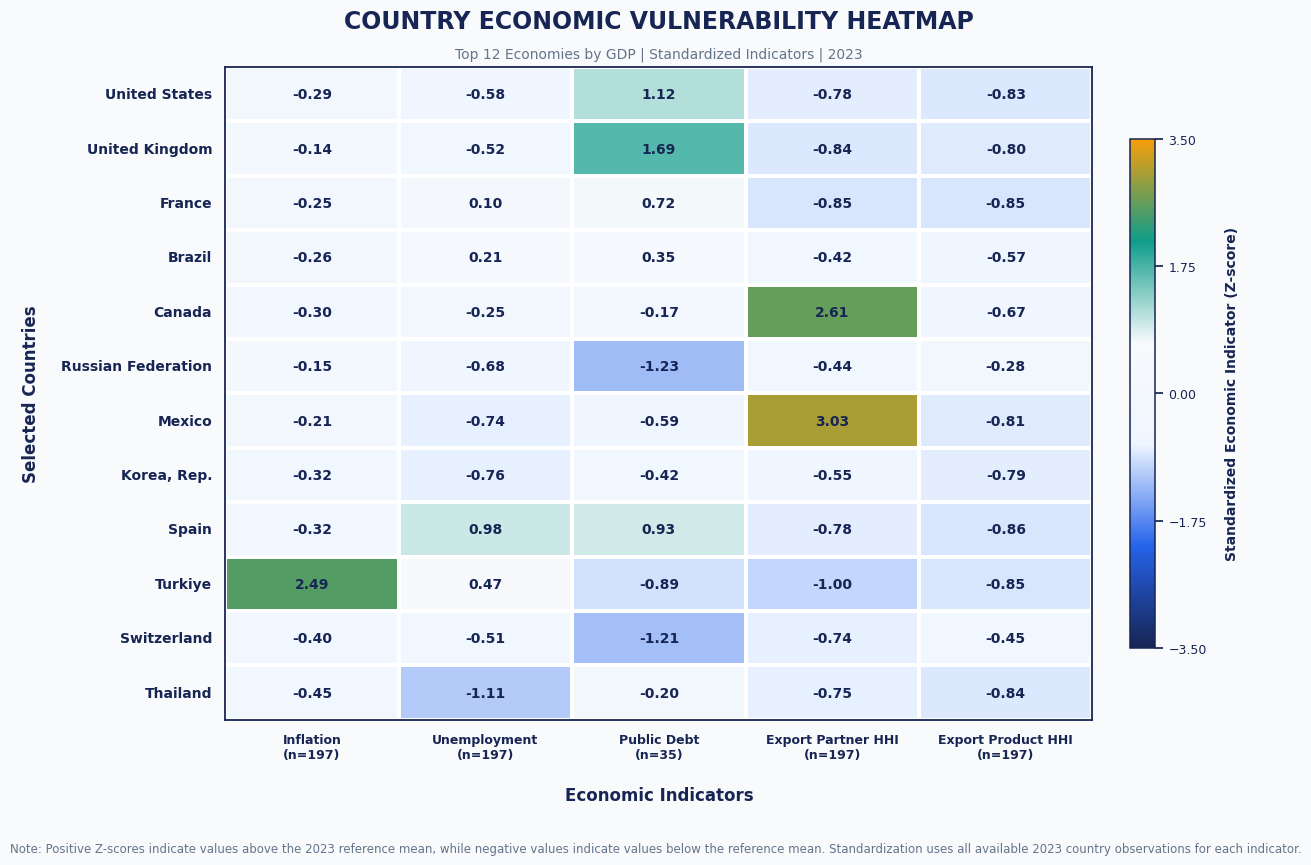

COUNTRY ECONOMIC VULNERABILITY ANALYSIS
Reference year: 2023
Selected countries: 12
Indicators: 5

STANDARDIZED DATA:
                    Inflation\n(n=197)  Unemployment\n(n=197)  Public Debt\n(n=35)  Export Partner HHI\n(n=197)  Export Product HHI\n(n=197)
country_name                                                                                                                                
United States                   -0.291                 -0.579                1.116                       -0.779                       -0.831
United Kingdom                  -0.141                 -0.516                1.692                       -0.841                       -0.804
France                          -0.248                  0.096                0.717                       -0.854                       -0.852
Brazil                          -0.264                  0.207                0.354                       -0.418                       -0.573
Canada                          -0.3

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from matplotlib.colors import LinearSegmentedColormap, Normalize

df = pd.read_csv("Cleaned-Dataset.csv")

NAVY = "#172554"
BLUE = "#2563EB"
TEAL = "#0F9D8A"
ORANGE = "#F59E0B"
GREY = "#64748B"
BACKGROUND = "#F8FAFC"

economic_cmap = LinearSegmentedColormap.from_list(
    "Economic_Vulnerability",
    [NAVY, BLUE, "#EFF6FF", BACKGROUND, TEAL, ORANGE],
    N=256
)

columns = {
    "Inflation (CPI %)": "Inflation",
    "Unemployment Rate (%)": "Unemployment",
    "Public Debt (% of GDP)": "Public Debt",
    "export_partner_hhi": "Export Partner HHI",
    "export_product_hhi": "Export Product HHI"
}

required = ["year", "country_name", "GDP (Current USD)"] + list(columns)
missing = [col for col in required if col not in df.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

numeric_columns = ["year", "GDP (Current USD)"] + list(columns)

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.replace([np.inf, -np.inf], np.nan)
reference = df[df["year"] == 2023].copy()

complete = reference.dropna(subset=["GDP (Current USD)"] + list(columns)).copy()
selected = complete.nlargest(12, "GDP (Current USD)").copy()

if len(selected) < 12:
    raise ValueError("Fewer than 12 countries have complete observations.")

selected = selected.sort_values("GDP (Current USD)", ascending=False)

data = selected.set_index("country_name")[list(columns)].rename(columns=columns).copy()

standardization_info = {}

for original, label in columns.items():
    reference_values = reference[original].dropna()
    mean = reference_values.mean()
    std = reference_values.std()

    if pd.isna(std) or std == 0:
        raise ValueError(f"Cannot standardize {label}: standard deviation is zero or missing.")

    data[label] = (data[label] - mean) / std

    standardization_info[label] = {
        "Mean": mean,
        "Standard Deviation": std,
        "Available Countries": len(reference_values)
    }

data.columns = [
    f"{label}\n(n={standardization_info[label]['Available Countries']})"
    for label in data.columns
]

max_abs = np.nanmax(np.abs(data.values))
color_limit = max(1, np.ceil(max_abs * 2) / 2)
norm = Normalize(vmin=-color_limit, vmax=color_limit)

sns.set_theme(style="white", context="notebook")

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.titlesize": 17, "axes.titleweight": "bold",
    "figure.facecolor": BACKGROUND, "axes.facecolor": "white",
    "axes.edgecolor": NAVY, "axes.linewidth": 1.3,
    "xtick.color": NAVY, "ytick.color": NAVY, "text.color": NAVY
})

fig, ax = plt.subplots(figsize=(13, 9))
fig.patch.set_facecolor(BACKGROUND)

sns.heatmap(
    data, annot=False, cmap=economic_cmap, center=0,
    vmin=-color_limit, vmax=color_limit,
    linewidths=1.6, linecolor="white",
    cbar_kws={"shrink": 0.78, "pad": 0.035, "ticks": np.linspace(-color_limit, color_limit, 5)},
    ax=ax
)

for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        value = data.iloc[i, j]

        if pd.notna(value):
            rgba = economic_cmap(norm(value))
            luminance = 0.2126 * rgba[0] + 0.7152 * rgba[1] + 0.0722 * rgba[2]
            text_color = "white" if luminance < 0.48 else NAVY

            ax.text(
                j + 0.5, i + 0.5, f"{value:.2f}",
                ha="center", va="center", fontsize=10,
                fontweight="bold", color=text_color
            )

ax.set_title("COUNTRY ECONOMIC VULNERABILITY HEATMAP", fontsize=17, fontweight="bold", color=NAVY, pad=28)

ax.text(
    0.5, 1.015, "Top 12 Economies by GDP | Standardized Indicators | 2023",
    transform=ax.transAxes, ha="center", fontsize=10, color=GREY
)

ax.set_xlabel("Economic Indicators", fontsize=12, fontweight="bold", color=NAVY, labelpad=18)
ax.set_ylabel("Selected Countries", fontsize=12, fontweight="bold", color=NAVY, labelpad=15)

plt.xticks(rotation=0, ha="center", fontsize=9, fontweight="semibold")
plt.yticks(rotation=0, fontsize=10, fontweight="semibold")

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=9, colors=NAVY)
colorbar.set_label("Standardized Economic Indicator (Z-score)", fontsize=10, fontweight="bold", color=NAVY, labelpad=13)
colorbar.outline.set_edgecolor(NAVY)
colorbar.outline.set_linewidth(1.1)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color(NAVY)
    spine.set_linewidth(1.3)

fig.text(
    0.5, 0.015,
    "Note: Positive Z-scores indicate values above the 2023 reference mean, "
    "while negative values indicate values below the reference mean. "
    "Standardization uses all available 2023 country observations for each indicator.",
    ha="center", fontsize=8.5, color=GREY
)

plt.tight_layout(rect=[0, 0.05, 1, 0.97])
plt.savefig("Plot_22_Improved.png", dpi=350, bbox_inches="tight", facecolor=BACKGROUND)
plt.show()

print("COUNTRY ECONOMIC VULNERABILITY ANALYSIS")
print("Reference year: 2023")
print("Selected countries:", len(data))
print("Indicators:", len(data.columns))

print("\nSTANDARDIZED DATA:")
print(data.round(3).to_string())

print("\nSTANDARDIZATION INFORMATION:")
print(pd.DataFrame(standardization_info).T.round(3).to_string())

files.download("Plot_22_Improved.png")


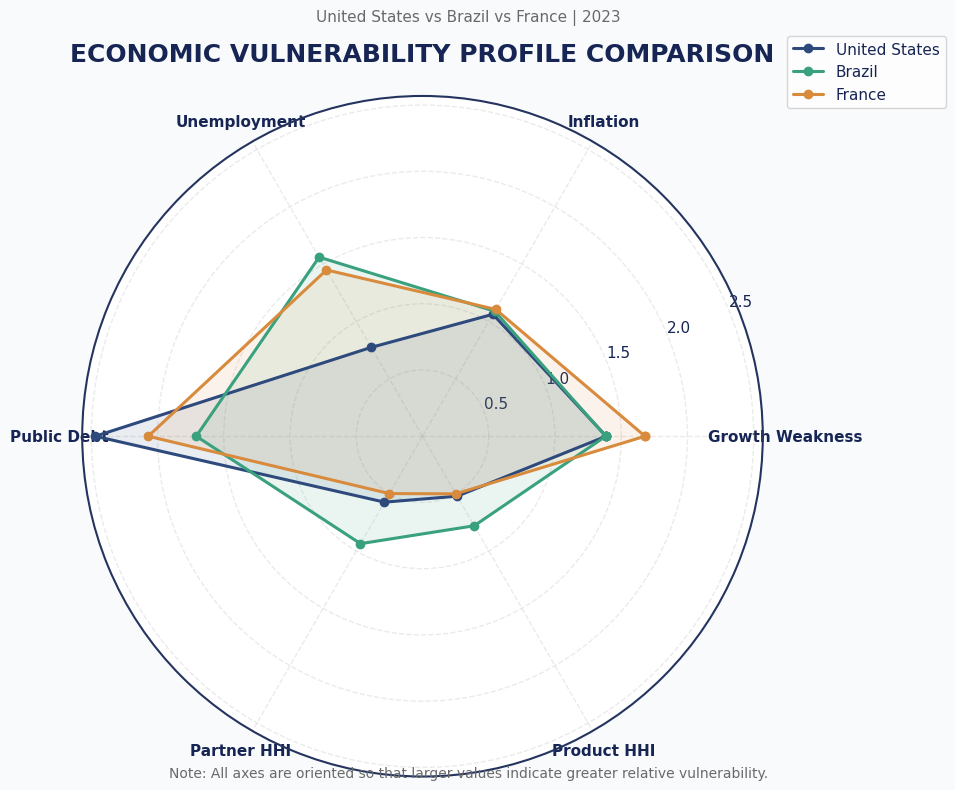

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("Cleaned-Dataset.csv")

countries = ["United States", "Brazil", "France"]
columns = [
    "GDP Growth (% Annual)", "Inflation (CPI %)", "Unemployment Rate (%)",
    "Public Debt (% of GDP)", "export_partner_hhi", "export_product_hhi"
]

reference = df[df["year"] == 2023].copy()
data = reference[reference["country_name"].isin(countries)].copy()

mean = reference[columns].mean()
std = reference[columns].std()
z = (data[columns] - mean) / std

z["GDP Growth (% Annual)"] = -z["GDP Growth (% Annual)"]

z = z.rename(columns={
    "GDP Growth (% Annual)": "Growth Weakness",
    "Inflation (CPI %)": "Inflation",
    "Unemployment Rate (%)": "Unemployment",
    "Public Debt (% of GDP)": "Public Debt",
    "export_partner_hhi": "Partner HHI",
    "export_product_hhi": "Product HHI"
})

z = z + abs(z.min().min()) + 0.5

labels = list(z.columns)
angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
angles += angles[:1]

colors = {"United States": "#2E4A7D", "Brazil": "#3AA17E", "France": "#D88A3D"}

fig, ax = plt.subplots(figsize=(9, 8), subplot_kw={"polar": True})

for country in countries:
    row = z[data["country_name"] == country].iloc[0].tolist()
    row += row[:1]
    ax.plot(angles, row, linewidth=2.2, marker="o", label=country, color=colors[country])
    ax.fill(angles, row, alpha=0.10, color=colors[country])

ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=11, fontweight="bold")

plt.title("ECONOMIC VULNERABILITY PROFILE COMPARISON", fontsize=18, fontweight="bold", pad=25)
plt.suptitle("United States vs Brazil vs France | 2023", y=0.98, fontsize=11, color="dimgray")

ax.grid(True, linestyle="--", alpha=0.4)
ax.spines["polar"].set_color("#24345F")
ax.spines["polar"].set_linewidth(1.5)

plt.legend(loc="upper right", bbox_to_anchor=(1.28, 1.10), frameon=True)

plt.figtext(
    0.5, 0.02,
    "Note: All axes are oriented so that larger values indicate greater relative vulnerability.",
    ha="center", fontsize=10, color="dimgray"
)

plt.tight_layout()
plt.savefig("Improved_Radar_Profile.png", dpi=300, bbox_inches="tight")
plt.show()

In [18]:

df["year"] = pd.to_numeric(df["year"])
df["GDP Growth (% Annual)"] = pd.to_numeric(df["GDP Growth (% Annual)"], errors="coerce")

df = df.sort_values(["country_iso3", "year"]).copy()

volatility_results = []

for country, group in df.groupby("country_iso3"):
    growth = group.set_index("year")["GDP Growth (% Annual)"].reindex(range(2010, 2025))
    rolling_volatility = growth.rolling(window=5, min_periods=3).std()

    temp = rolling_volatility.rename("GDP Growth Volatility").reset_index()
    temp["country_iso3"] = country
    volatility_results.append(temp)

volatility_df = pd.concat(volatility_results, ignore_index=True)

df = df.merge(volatility_df, on=["country_iso3", "year"], how="left")

print("GDP GROWTH VOLATILITY RESULTS")

display(df[["country_name", "year", "GDP Growth (% Annual)", "GDP Growth Volatility"]].head(15))

print("\nVOLATILITY SUMMARY")
display(df["GDP Growth Volatility"].describe())

print("\nMissing volatility observations:", df["GDP Growth Volatility"].isna().sum())


GDP GROWTH VOLATILITY RESULTS


,country_name,year,GDP Growth (% Annual),GDP Growth Volatility
0,Aruba,2010,-2.733457,NaN
1,Aruba,2011,3.369237,NaN
2,Aruba,2012,-1.040800,3.150566
3,Aruba,2013,6.431483,4.170980
4,Aruba,2014,-1.586575,3.867993
5,Aruba,2015,-0.623626,3.468622
6,Aruba,2016,1.719625,3.298040
7,Aruba,2017,7.048533,3.973787
8,Aruba,2018,2.397085,3.363500
9,Aruba,2019,-2.232440,3.533736



VOLATILITY SUMMARY


,GDP Growth Volatility
count,2557.000000
mean,3.526708
std,4.384107
min,0.000000
25%,1.266538
50%,2.468505
75%,4.195954
max,69.005840



Missing volatility observations: 394


In [19]:

df["Fiscal Balance"] = (
    pd.to_numeric(df["Government Revenue (% of GDP)"], errors="coerce") -
    pd.to_numeric(df["Government Expense (% of GDP)"], errors="coerce")
)

df["Fiscal Deficit"] = np.maximum(0, -df["Fiscal Balance"])

indicators = {
    "export_partner_hhi": "Partner_HHI_Norm",
    "export_product_hhi": "Product_HHI_Norm",
    "GDP Growth Volatility": "GDP_Volatility_Norm",
    "Inflation (CPI %)": "Inflation_Norm",
    "Unemployment Rate (%)": "Unemployment_Norm",
    "Public Debt (% of GDP)": "Public_Debt_Norm",
    "Fiscal Deficit": "Fiscal_Deficit_Norm"
}

def min_max_normalize(series):
    minimum, maximum = series.min(), series.max()

    if pd.isna(minimum) or pd.isna(maximum) or maximum == minimum:
        return pd.Series(np.nan, index=series.index)

    return (series - minimum) / (maximum - minimum)

for original, normalized in indicators.items():
    df[normalized] = min_max_normalize(pd.to_numeric(df[original], errors="coerce"))

normalized_columns = list(indicators.values())

print("NORMALIZED INDICATORS")
display(df[normalized_columns].head(10))

print("\nNORMALIZATION SUMMARY")
display(df[normalized_columns].describe().T)

print("\nMISSING VALUES AFTER NORMALIZATION")
display(df[normalized_columns].isnull().sum())


NORMALIZED INDICATORS


,Partner_HHI_Norm,Product_HHI_Norm,GDP_Volatility_Norm,Inflation_Norm,Unemployment_Norm,Public_Debt_Norm,Fiscal_Deficit_Norm
0,0.092495,0.157073,NaN,0.015545,0.190334,NaN,0.046817
1,0.518954,0.612664,NaN,0.019514,0.182393,NaN,0.013767
2,0.212375,0.401764,0.045657,0.012972,0.183825,NaN,0.000515
3,0.054808,0.168715,0.060444,0.007653,0.175572,NaN,0.010111
4,0.098013,0.205678,0.056053,0.012607,0.174863,NaN,0.018799
5,0.080992,0.092636,0.050266,0.012701,0.171361,NaN,0.021328
6,0.126241,0.072743,0.047794,0.010208,0.161874,NaN,0.037088
7,0.067545,0.088613,0.057586,0.010036,0.154032,NaN,0.018171
8,0.221260,0.149279,0.048742,0.018290,0.144800,NaN,0.000000
9,0.142657,0.137215,0.051209,0.019409,0.139482,NaN,0.004178



NORMALIZATION SUMMARY


,count,mean,std,min,25%,50%,75%,max
Partner_HHI_Norm,2951.0,0.146834,0.156703,0.0,0.047016,0.089030,0.187048,1.0
Product_HHI_Norm,2951.0,0.156213,0.189079,0.0,0.023316,0.085886,0.207184,1.0
GDP_Volatility_Norm,2557.0,0.051107,0.063532,0.0,0.018354,0.035772,0.060806,1.0
Inflation_Norm,2951.0,0.022799,0.033660,0.0,0.014492,0.017527,0.022722,1.0
Unemployment_Norm,2951.0,0.212946,0.163433,0.0,0.102967,0.160016,0.276795,1.0
Public_Debt_Norm,844.0,0.242185,0.164007,0.0,0.128210,0.200309,0.323549,1.0
Fiscal_Deficit_Norm,2951.0,0.048667,0.091232,0.0,0.000000,0.018799,0.058226,1.0



MISSING VALUES AFTER NORMALIZATION


,0
Partner_HHI_Norm,0
Product_HHI_Norm,0
GDP_Volatility_Norm,394
Inflation_Norm,0
Unemployment_Norm,0
Public_Debt_Norm,2107
Fiscal_Deficit_Norm,0


In [ ]:

variables = [
    "export_partner_hhi",
    "export_product_hhi",
    "GDP Growth Volatility",
    "Inflation (CPI %)",
    "Unemployment Rate (%)",
    "Public Debt (% of GDP)",
    "Fiscal Deficit"
]

for col in variables:

    print("\n" + "=" * 55)
    print("VARIABLE:", col)

    print("\nMinimum and Maximum:")
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())

    print("\nFive Highest Observations:")

    display(
        df.nlargest(5, col)[
            ["country_name", "year", col]
        ]
    )



VARIABLE: export_partner_hhi

Minimum and Maximum:
Minimum: 316.3490925648709
Maximum: 9943.489344856896

Five Highest Observations:


,country_name,year,export_partner_hhi
2429,South Sudan,2013,9943.489345
2431,South Sudan,2015,9897.125797
2432,South Sudan,2016,9736.168095
2430,South Sudan,2014,9679.611285
2433,South Sudan,2017,8929.290169



VARIABLE: export_product_hhi

Minimum and Maximum:
Minimum: 30.435811881099525
Maximum: 9965.641788296252

Five Highest Observations:


,country_name,year,export_product_hhi
2430,South Sudan,2014,9965.641788
2429,South Sudan,2013,9943.223522
2428,South Sudan,2012,9917.506941
2431,South Sudan,2015,9896.939435
2433,South Sudan,2017,9758.921834



VARIABLE: GDP Growth Volatility

Minimum and Maximum:
Minimum: 0.0
Maximum: 69.00583978891065

Five Highest Observations:


,country_name,year,GDP Growth Volatility
1532,Libya,2012,69.005840
1533,Libya,2013,58.548503
1534,Libya,2014,52.328233
1535,Libya,2015,52.255709
1648,"Macao SAR, China",2023,48.564618


... (4 outputs left out)


VARIABLE: Public Debt (% of GDP)

Minimum and Maximum:
Minimum: 1.84568513687825
Maximum: 249.366027184106

Five Highest Observations:


,country_name,year,Public Debt (% of GDP)
1060,Greece,2020,249.366027
1061,Greece,2021,233.448695
1361,Japan,2021,216.329365
1362,Japan,2022,216.213375
1360,Japan,2020,215.755541



VARIABLE: Fiscal Deficit

Minimum and Maximum:
Minimum: 0.0
Maximum: 47.9746151657207

Five Highest Observations:


,country_name,year,Fiscal Deficit
16,Afghanistan,2011,47.974615
15,Afghanistan,2010,39.771055
19,Afghanistan,2014,35.975569
2769,Ukraine,2023,35.203806
2140,Palau,2020,34.737681


In [20]:

print("LARGEST FISCAL DEFICITS")

display(df.nlargest(5, "Fiscal Deficit")[[
    "country_name", "year", "Government Revenue (% of GDP)",
    "Government Expense (% of GDP)", "Fiscal Balance", "Fiscal Deficit"
]])

print("\nLARGEST INFLATION OBSERVATIONS")

display(df.nlargest(5, "Inflation (CPI %)")[[
    "country_name", "year", "Inflation (CPI %)"
]])

revenue = pd.to_numeric(df["Government Revenue (% of GDP)"], errors="coerce")
expense = pd.to_numeric(df["Government Expense (% of GDP)"], errors="coerce")

check = df["Fiscal Deficit"] - np.maximum(0, expense - revenue)

print("\nFISCAL DEFICIT CALCULATION CHECK")
print("Maximum absolute difference:", check.abs().max())

print("\nHHI SCALE CHECK")

for col in ["export_partner_hhi", "export_product_hhi"]:
    print(f"{col} | Minimum: {df[col].min()} | Maximum: {df[col].max()}")


LARGEST FISCAL DEFICITS


,country_name,year,Government Revenue (% of GDP),Government Expense (% of GDP),Fiscal Balance,Fiscal Deficit
16,Afghanistan,2011,11.510161,59.484776,-47.974615,47.974615
15,Afghanistan,2010,11.091949,50.863005,-39.771055,39.771055
19,Afghanistan,2014,8.613731,44.589299,-35.975569,35.975569
2769,Ukraine,2023,31.260083,66.463888,-35.203806,35.203806
2140,Palau,2020,24.215914,58.953595,-34.737681,34.737681



LARGEST INFLATION OBSERVATIONS


,country_name,year,Inflation (CPI %)
2946,Zimbabwe,2020,557.201817
2432,South Sudan,2016,379.999586
2334,Sudan,2021,359.093041
2945,Zimbabwe,2019,255.304991
2837,"Venezuela, RB",2016,254.948535



FISCAL DEFICIT CALCULATION CHECK
Maximum absolute difference: 0.0

HHI SCALE CHECK
export_partner_hhi | Minimum: 316.3490925648709 | Maximum: 9943.489344856896
export_product_hhi | Minimum: 30.435811881099525 | Maximum: 9965.641788296252


In [23]:

df["Trade_Vulnerability"] = df["Partner_HHI_Norm"] + df["Product_HHI_Norm"]

print("TRADE VULNERABILITY - FIRST 10 ROWS")
display(df[["country_name", "year", "Partner_HHI_Norm", "Product_HHI_Norm", "Trade_Vulnerability"]].head(10))

print("\nTRADE VULNERABILITY SUMMARY")
display(df["Trade_Vulnerability"].describe())

print("\nHIGHEST TRADE VULNERABILITY")
display(df.nlargest(10, "Trade_Vulnerability")[["country_name", "year", "Trade_Vulnerability"]])

print("\nLOWEST TRADE VULNERABILITY")
display(df.nsmallest(10, "Trade_Vulnerability")[["country_name", "year", "Trade_Vulnerability"]])

print("\nMISSING VALUES:", df["Trade_Vulnerability"].isna().sum())


TRADE VULNERABILITY - FIRST 10 ROWS


,country_name,year,Partner_HHI_Norm,Product_HHI_Norm,Trade_Vulnerability
0,Aruba,2010,0.092495,0.157073,0.249568
1,Aruba,2011,0.518954,0.612664,1.131619
2,Aruba,2012,0.212375,0.401764,0.614139
3,Aruba,2013,0.054808,0.168715,0.223522
4,Aruba,2014,0.098013,0.205678,0.303691
5,Aruba,2015,0.080992,0.092636,0.173628
6,Aruba,2016,0.126241,0.072743,0.198984
7,Aruba,2017,0.067545,0.088613,0.156158
8,Aruba,2018,0.221260,0.149279,0.370540
9,Aruba,2019,0.142657,0.137215,0.279872



TRADE VULNERABILITY SUMMARY


,Trade_Vulnerability
count,2951.000000
mean,0.303047
std,0.291963
min,0.001578
25%,0.082464
50%,0.211909
75%,0.416654
max,1.997744



HIGHEST TRADE VULNERABILITY


,country_name,year,Trade_Vulnerability
2429,South Sudan,2013,1.997744
2431,South Sudan,2015,1.988269
2430,South Sudan,2014,1.972590
2432,South Sudan,2016,1.955340
2433,South Sudan,2017,1.873845
2434,South Sudan,2018,1.766523
811,Eritrea,2011,1.750608
2435,South Sudan,2019,1.672961
1034,Guinea-Bissau,2024,1.645587
2428,South Sudan,2012,1.632183



LOWEST TRADE VULNERABILITY


,country_name,year,Trade_Vulnerability
2708,Turkiye,2022,0.001578
2705,Turkiye,2019,0.001850
2707,Turkiye,2021,0.001874
2706,Turkiye,2020,0.001971
2709,Turkiye,2023,0.002871
2710,Turkiye,2024,0.003047
2704,Turkiye,2018,0.003771
2699,Turkiye,2013,0.005311
2700,Turkiye,2014,0.005330
2696,Turkiye,2010,0.007176



MISSING VALUES: 0


In [ ]:

macro_columns = ["GDP_Volatility_Norm", "Inflation_Norm", "Unemployment_Norm"]

df["Macroeconomic_Instability"] = df[macro_columns].mean(axis=1)
df.loc[df[macro_columns].isna().any(axis=1), "Macroeconomic_Instability"] = np.nan

print("MACROECONOMIC INSTABILITY - FIRST 10 ROWS")
display(df[["country_name", "year"] + macro_columns + ["Macroeconomic_Instability"]].head(10))

print("\nMACROECONOMIC INSTABILITY SUMMARY")
display(df["Macroeconomic_Instability"].describe())

print("\nHIGHEST MACROECONOMIC INSTABILITY")
display(df.nlargest(10, "Macroeconomic_Instability")[["country_name", "year", "Macroeconomic_Instability"]])

print("\nLOWEST MACROECONOMIC INSTABILITY")
display(df.nsmallest(10, "Macroeconomic_Instability")[["country_name", "year", "Macroeconomic_Instability"]])

print("\nMISSING VALUES:", df["Macroeconomic_Instability"].isna().sum())
print("VALID OBSERVATIONS:", df["Macroeconomic_Instability"].count())


MACROECONOMIC INSTABILITY - FIRST 10 ROWS


,country_name,year,GDP_Volatility_Norm,Inflation_Norm,Unemployment_Norm,Macroeconomic_Instability
0,Aruba,2010,NaN,0.015545,0.190334,NaN
1,Aruba,2011,NaN,0.019514,0.182393,NaN
2,Aruba,2012,0.045657,0.012972,0.183825,0.080818
3,Aruba,2013,0.060444,0.007653,0.175572,0.081223
4,Aruba,2014,0.056053,0.012607,0.174863,0.081174
5,Aruba,2015,0.050266,0.012701,0.171361,0.078109
6,Aruba,2016,0.047794,0.010208,0.161874,0.073292
7,Aruba,2017,0.057586,0.010036,0.154032,0.073885
8,Aruba,2018,0.048742,0.018290,0.144800,0.070611
9,Aruba,2019,0.051209,0.019409,0.139482,0.070034


MACROECONOMIC INSTABILITY SUMMARY


,Macroeconomic_Instability
count,2557.000000
mean,0.094937
std,0.062012
min,0.007738
25%,0.052873
50%,0.075854
75%,0.120051
max,0.519830


HIGHEST MACROECONOMIC INSTABILITY


,country_name,year,Macroeconomic_Instability
1532,Libya,2012,0.519830
1533,Libya,2013,0.470082
2432,South Sudan,2016,0.459440
1535,Libya,2015,0.447592
2946,Zimbabwe,2020,0.442498
1534,Libya,2014,0.439753
1536,Libya,2016,0.419133
2528,Eswatini,2022,0.355414
2529,Eswatini,2023,0.354770
2917,South Africa,2021,0.346830


LOWEST MACROECONOMIC INSTABILITY


,country_name,year,Macroeconomic_Instability
1417,Cambodia,2017,0.007738
1419,Cambodia,2019,0.007979
1418,Cambodia,2018,0.008386
1415,Cambodia,2015,0.009123
2256,Qatar,2016,0.010725
1944,Niger,2019,0.011694
1416,Cambodia,2016,0.013089
1942,Niger,2017,0.013965
1794,Myanmar,2019,0.014170
2600,Thailand,2019,0.014381


MISSING VALUES:
394
VALID OBSERVATIONS:
2557


In [24]:

fiscal_columns = ["Public_Debt_Norm", "Fiscal_Deficit_Norm"]

df["Fiscal_Vulnerability"] = df[fiscal_columns].mean(axis=1)
df.loc[df[fiscal_columns].isna().any(axis=1), "Fiscal_Vulnerability"] = np.nan

print("FISCAL VULNERABILITY - FIRST 10 ROWS")
display(df[["country_name", "year"] + fiscal_columns + ["Fiscal_Vulnerability"]].head(10))

print("\nFISCAL VULNERABILITY SUMMARY")
display(df["Fiscal_Vulnerability"].describe())

print("\nHIGHEST FISCAL VULNERABILITY")
display(df.nlargest(10, "Fiscal_Vulnerability")[["country_name", "year", "Fiscal_Vulnerability"]])

print("\nLOWEST FISCAL VULNERABILITY")
display(df.nsmallest(10, "Fiscal_Vulnerability")[["country_name", "year", "Fiscal_Vulnerability"]])

print("\nMISSING VALUES:", df["Fiscal_Vulnerability"].isna().sum())
print("VALID OBSERVATIONS:", df["Fiscal_Vulnerability"].count())


FISCAL VULNERABILITY - FIRST 10 ROWS


,country_name,year,Public_Debt_Norm,Fiscal_Deficit_Norm,Fiscal_Vulnerability
0,Aruba,2010,NaN,0.046817,NaN
1,Aruba,2011,NaN,0.013767,NaN
2,Aruba,2012,NaN,0.000515,NaN
3,Aruba,2013,NaN,0.010111,NaN
4,Aruba,2014,NaN,0.018799,NaN
5,Aruba,2015,NaN,0.021328,NaN
6,Aruba,2016,NaN,0.037088,NaN
7,Aruba,2017,NaN,0.018171,NaN
8,Aruba,2018,NaN,0.000000,NaN
9,Aruba,2019,NaN,0.004178,NaN



FISCAL VULNERABILITY SUMMARY


,Fiscal_Vulnerability
count,844.000000
mean,0.152243
std,0.103278
min,0.008903
25%,0.076807
50%,0.123547
75%,0.205072
max,0.646623



HIGHEST FISCAL VULNERABILITY


,country_name,year,Fiscal_Vulnerability
1060,Greece,2020,0.646623
1061,Greece,2021,0.581270
1053,Greece,2013,0.558613
955,United Kingdom,2020,0.542271
1230,Ireland,2010,0.490059
1725,Marshall Islands,2010,0.489554
1052,Greece,2012,0.476110
1055,Greece,2015,0.467821
1726,Marshall Islands,2011,0.466485
1062,Greece,2022,0.462992



LOWEST FISCAL VULNERABILITY


,country_name,year,Fiscal_Vulnerability
78,United Arab Emirates,2013,0.008903
165,Azerbaijan,2010,0.009171
2373,Solomon Islands,2015,0.009882
2376,Solomon Islands,2018,0.011797
2282,Russian Federation,2012,0.013546
2281,Russian Federation,2011,0.013727
1366,Kazakhstan,2011,0.014051
2283,Russian Federation,2013,0.014588
1365,Kazakhstan,2010,0.015508
1367,Kazakhstan,2012,0.017478



MISSING VALUES: 2107
VALID OBSERVATIONS: 844


In [27]:
efi_columns = ["Trade_Vulnerability", "Macroeconomic_Instability", "Fiscal_Vulnerability"]

print("Missing columns:", [col for col in efi_columns if col not in df.columns])

Missing columns: ['Macroeconomic_Instability']


In [28]:

required_columns = [
    "Partner_HHI_Norm", "Product_HHI_Norm",
    "GDP_Volatility_Norm", "Inflation_Norm", "Unemployment_Norm",
    "Public_Debt_Norm", "Fiscal_Deficit_Norm"
]

missing = [col for col in required_columns if col not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

# STEP 5.4: TRADE VULNERABILITY

trade_columns = ["Partner_HHI_Norm", "Product_HHI_Norm"]

df["Trade_Vulnerability"] = df[trade_columns].mean(axis=1)
df.loc[df[trade_columns].isna().any(axis=1), "Trade_Vulnerability"] = np.nan

print("TRADE VULNERABILITY")
display(df[["country_name", "year"] + trade_columns + ["Trade_Vulnerability"]].head(10))

print("\nTRADE VULNERABILITY SUMMARY")
display(df["Trade_Vulnerability"].describe())

print("\nHIGHEST TRADE VULNERABILITY")
display(df.nlargest(10, "Trade_Vulnerability")[["country_name", "year", "Trade_Vulnerability"]])

print("\nLOWEST TRADE VULNERABILITY")
display(df.nsmallest(10, "Trade_Vulnerability")[["country_name", "year", "Trade_Vulnerability"]])

# STEP 5.5: MACROECONOMIC INSTABILITY

macro_columns = ["GDP_Volatility_Norm", "Inflation_Norm", "Unemployment_Norm"]

df["Macroeconomic_Instability"] = df[macro_columns].mean(axis=1)
df.loc[df[macro_columns].isna().any(axis=1), "Macroeconomic_Instability"] = np.nan

print("\nMACROECONOMIC INSTABILITY")
display(df[["country_name", "year"] + macro_columns + ["Macroeconomic_Instability"]].head(10))

print("\nMACROECONOMIC INSTABILITY SUMMARY")
display(df["Macroeconomic_Instability"].describe())

print("\nHIGHEST MACROECONOMIC INSTABILITY")
display(df.nlargest(10, "Macroeconomic_Instability")[["country_name", "year", "Macroeconomic_Instability"]])

print("\nLOWEST MACROECONOMIC INSTABILITY")
display(df.nsmallest(10, "Macroeconomic_Instability")[["country_name", "year", "Macroeconomic_Instability"]])

# STEP 5.6: FISCAL VULNERABILITY

fiscal_columns = ["Public_Debt_Norm", "Fiscal_Deficit_Norm"]

df["Fiscal_Vulnerability"] = df[fiscal_columns].mean(axis=1)
df.loc[df[fiscal_columns].isna().any(axis=1), "Fiscal_Vulnerability"] = np.nan

print("\nFISCAL VULNERABILITY")
display(df[["country_name", "year"] + fiscal_columns + ["Fiscal_Vulnerability"]].head(10))

print("\nFISCAL VULNERABILITY SUMMARY")
display(df["Fiscal_Vulnerability"].describe())

print("\nHIGHEST FISCAL VULNERABILITY")
display(df.nlargest(10, "Fiscal_Vulnerability")[["country_name", "year", "Fiscal_Vulnerability"]])

print("\nLOWEST FISCAL VULNERABILITY")
display(df.nsmallest(10, "Fiscal_Vulnerability")[["country_name", "year", "Fiscal_Vulnerability"]])

# STEP 5.7: CONSTRUCTION OF EFI

efi_columns = ["Trade_Vulnerability", "Macroeconomic_Instability", "Fiscal_Vulnerability"]

df["EFI"] = df[efi_columns].mean(axis=1)
df.loc[df[efi_columns].isna().any(axis=1), "EFI"] = np.nan

print("\nEFI - FIRST 10 ROWS")
display(df[["country_name", "year"] + efi_columns + ["EFI"]].head(10))

print("\nEFI SUMMARY")
display(df["EFI"].describe())

print("\nHIGHEST EFI OBSERVATIONS")
display(df.nlargest(10, "EFI")[["country_name", "year", "EFI"]])

print("\nLOWEST EFI OBSERVATIONS")
display(df.nsmallest(10, "EFI")[["country_name", "year", "EFI"]])

print("\nFINAL EFI RESULTS")
print("Missing EFI:", df["EFI"].isna().sum())
print("Valid EFI:", df["EFI"].count())
print("Total observations:", len(df))
print("Minimum EFI:", df["EFI"].min())
print("Maximum EFI:", df["EFI"].max())

print("\nDIMENSION WEIGHTS")
print("Trade Vulnerability: 33.33%")
print("Macroeconomic Instability: 33.33%")
print("Fiscal Vulnerability: 33.33%")


TRADE VULNERABILITY


,country_name,year,Partner_HHI_Norm,Product_HHI_Norm,Trade_Vulnerability
0,Aruba,2010,0.092495,0.157073,0.124784
1,Aruba,2011,0.518954,0.612664,0.565809
2,Aruba,2012,0.212375,0.401764,0.307070
3,Aruba,2013,0.054808,0.168715,0.111761
4,Aruba,2014,0.098013,0.205678,0.151846
5,Aruba,2015,0.080992,0.092636,0.086814
6,Aruba,2016,0.126241,0.072743,0.099492
7,Aruba,2017,0.067545,0.088613,0.078079
8,Aruba,2018,0.221260,0.149279,0.185270
9,Aruba,2019,0.142657,0.137215,0.139936



TRADE VULNERABILITY SUMMARY


,Trade_Vulnerability
count,2951.000000
mean,0.151524
std,0.145982
min,0.000789
25%,0.041232
50%,0.105954
75%,0.208327
max,0.998872



HIGHEST TRADE VULNERABILITY


,country_name,year,Trade_Vulnerability
2429,South Sudan,2013,0.998872
2431,South Sudan,2015,0.994135
2430,South Sudan,2014,0.986295
2432,South Sudan,2016,0.977670
2433,South Sudan,2017,0.936923
2434,South Sudan,2018,0.883261
811,Eritrea,2011,0.875304
2435,South Sudan,2019,0.836481
1034,Guinea-Bissau,2024,0.822794
2428,South Sudan,2012,0.816091


... (23 outputs left out)

,country_name,year,EFI
2132,Palau,2012,0.338096
2133,Palau,2013,0.310977
1053,Greece,2013,0.296113
1060,Greece,2020,0.279873
235,Burkina Faso,2020,0.270742
1727,Marshall Islands,2012,0.265369
1061,Greece,2021,0.258704
2137,Palau,2017,0.257315
1054,Greece,2014,0.257165
1052,Greece,2012,0.255105



LOWEST EFI OBSERVATIONS


,country_name,year,EFI
2593,Thailand,2012,0.033136
849,Estonia,2019,0.034348
2598,Thailand,2017,0.035355
2599,Thailand,2018,0.035632
2596,Thailand,2015,0.035647
2600,Thailand,2019,0.035648
2595,Thailand,2014,0.036127
2597,Thailand,2016,0.036234
2594,Thailand,2013,0.037485
847,Estonia,2017,0.037782



FINAL EFI RESULTS
Missing EFI: 2237
Valid EFI: 714
Total observations: 2951
Minimum EFI: 0.03313603013439911
Maximum EFI: 0.3380963542079458

DIMENSION WEIGHTS
Trade Vulnerability: 33.33%
Macroeconomic Instability: 33.33%
Fiscal Vulnerability: 33.33%


In [29]:

valid_efi = df[df["EFI"].notna()].copy()

country_coverage = (
    valid_efi.groupby("country_name")
    .agg(
        Valid_Years=("EFI", "count"),
        First_Year=("year", "min"),
        Last_Year=("year", "max"),
        Average_EFI=("EFI", "mean")
    )
    .reset_index()
    .sort_values("Valid_Years", ascending=False)
)

print("EFI COVERAGE BY COUNTRY")
display(country_coverage)

print("\nCOUNTRY COVERAGE SUMMARY")
display(country_coverage["Valid_Years"].describe())

print("\nCOUNTRIES WITH VALID EFI:", valid_efi["country_name"].nunique())

year_coverage = (
    valid_efi.groupby("year")
    .agg(
        Valid_Countries=("EFI", "count"),
        Average_EFI=("EFI", "mean")
    )
    .reset_index()
)

print("\nEFI COVERAGE BY YEAR")
display(year_coverage)


EFI COVERAGE BY COUNTRY


,country_name,Valid_Years,First_Year,Last_Year,Average_EFI
3,Austria,12,2012,2023,0.102694
15,Bulgaria,12,2012,2023,0.056974
5,"Bahamas, The",12,2012,2023,0.145697
14,Brazil,12,2012,2023,0.127411
12,Bosnia and Herzegovina,12,2012,2023,0.110194
...,...,...,...,...,...
28,Guatemala,2,2012,2013,0.065753
41,Liberia,1,2012,2012,0.047680
19,"Congo, Dem. Rep.",1,2022,2022,0.138206
71,Tunisia,1,2012,2012,0.122978



COUNTRY COVERAGE SUMMARY


,Valid_Years
count,81.000000
mean,8.814815
std,3.571103
min,1.000000
25%,7.000000
50%,10.000000
75%,12.000000
max,12.000000



COUNTRIES WITH VALID EFI: 81

EFI COVERAGE BY YEAR


,year,Valid_Countries,Average_EFI
0,2012,64,0.115290
1,2013,64,0.113726
2,2014,64,0.112383
3,2015,63,0.113760
4,2016,63,0.114371
5,2017,63,0.111680
6,2018,66,0.111034
7,2019,67,0.113199
8,2020,62,0.142027
9,2021,53,0.128939


In [ ]:
valid_efi = df[df["EFI"].notna()].copy()
threshold_low = valid_efi["EFI"].quantile(1/3)
threshold_high = valid_efi["EFI"].quantile(2/3)

print("CLASSIFICATION THRESHOLDS")
print("33rd Percentile:", threshold_low)
print("67th Percentile:", threshold_high)
valid_efi["EFI_Category"] = np.select(
    [
        valid_efi["EFI"] <= threshold_low,
        valid_efi["EFI"] <= threshold_high
    ],
    [
        "Low Fragility",
        "Moderate Fragility"
    ],
    default="High Fragility"
)
summary = (
    valid_efi["EFI_Category"]
    .value_counts()
    .reindex(
        ["Low Fragility", "Moderate Fragility", "High Fragility"],
        fill_value=0
    )
    .reset_index()
)

summary.columns = ["Category", "Number of Observations"]

summary["Percentage"] = (
    summary["Number of Observations"] / len(valid_efi) * 100
)

print("CLASSIFICATION SUMMARY")
display(summary)
print("CLASSIFIED OBSERVATIONS")

display(
    valid_efi[
        ["country_name", "year", "EFI", "EFI_Category"]
    ].head(15)
)
print("Total classified:", len(valid_efi))
print("Missing EFI:", df["EFI"].isna().sum())


CLASSIFICATION THRESHOLDS
33rd Percentile: 0.09048072186831008
67th Percentile: 0.1348017139149956
CLASSIFICATION SUMMARY


,Category,Number of Observations,Percentage
0,Low Fragility,238,33.333333
1,Moderate Fragility,238,33.333333
2,High Fragility,238,33.333333


CLASSIFIED OBSERVATIONS


,country_name,year,EFI,EFI_Category
47,Albania,2012,0.135217,High Fragility
48,Albania,2013,0.153116,High Fragility
49,Albania,2014,0.153842,High Fragility
50,Albania,2015,0.148451,High Fragility
51,Albania,2016,0.147020,High Fragility
52,Albania,2017,0.138041,High Fragility
53,Albania,2018,0.122228,Moderate Fragility
54,Albania,2019,0.123350,Moderate Fragility
55,Albania,2020,0.135681,High Fragility
56,Albania,2021,0.131116,Moderate Fragility


Total classified: 714
Missing EFI: 2237


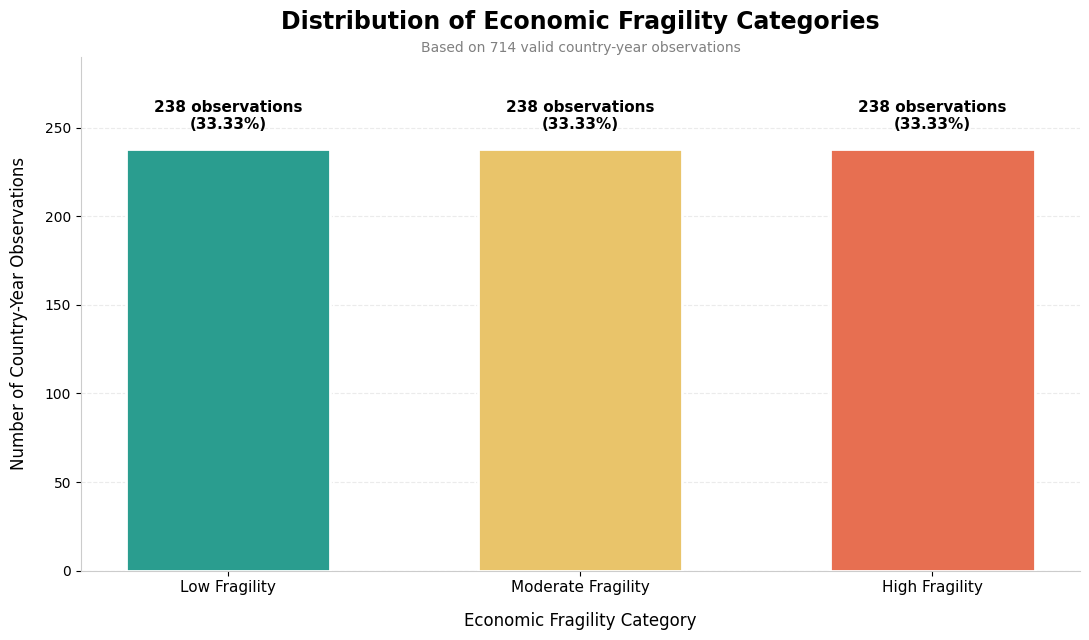

In [ ]:

import matplotlib.pyplot as plt
import numpy as np
categories = [
    "Low Fragility",
    "Moderate Fragility",
    "High Fragility"
]

counts = [238, 238, 238]
percentages = [33.33, 33.33, 33.33]
colors = [
    "#2A9D8F",  # Teal - Low
    "#E9C46A",  # Gold - Moderate
    "#E76F51"   # Coral - High
]
fig, ax = plt.subplots(figsize=(11, 6.5))

bars = ax.bar(
    categories,
    counts,
    color=colors,
    width=0.58,
    edgecolor="white",
    linewidth=2,
    zorder=3
)
for bar, count, percentage in zip(bars, counts, percentages):

    ax.annotate(
        f"{count} observations\n({percentage:.2f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )
ax.set_title(
    "Distribution of Economic Fragility Categories",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Economic Fragility Category",
    fontsize=12,
    labelpad=12
)

ax.set_ylabel(
    "Number of Country-Year Observations",
    fontsize=12,
    labelpad=12
)
ax.set_ylim(0, 290)
ax.set_yticks(np.arange(0, 251, 50))

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25,
    zorder=0
)

ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("#CCCCCC")
ax.spines["bottom"].set_color("#CCCCCC")

ax.tick_params(axis="x", labelsize=11)
ax.tick_params(axis="y", labelsize=10)
ax.text(
    0.5, 1.01,
    "Based on 714 valid country-year observations",
    transform=ax.transAxes,
    ha="center",
    fontsize=10,
    color="gray"
)
plt.tight_layout()

plt.savefig(
    "EFI_Classification_Professional.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

import pandas as pd
import numpy as np
dimensions = [
    "Trade_Vulnerability",
    "Macroeconomic_Instability",
    "Fiscal_Vulnerability"
]
sensitivity_df = df.dropna(
    subset=dimensions
).copy()
sensitivity_df["EFI_Baseline"] = (
    sensitivity_df[dimensions].mean(axis=1)
)

print("NUMBER OF OBSERVATIONS:",
      len(sensitivity_df))
scenarios = {
    "Baseline": {
        "Trade_Vulnerability": 1/3,
        "Macroeconomic_Instability": 1/3,
        "Fiscal_Vulnerability": 1/3
    },

    "Trade_Oriented": {
        "Trade_Vulnerability": 0.50,
        "Macroeconomic_Instability": 0.25,
        "Fiscal_Vulnerability": 0.25
    },

    "Macroeconomic_Oriented": {
        "Trade_Vulnerability": 0.25,
        "Macroeconomic_Instability": 0.50,
        "Fiscal_Vulnerability": 0.25
    },

    "Fiscal_Oriented": {
        "Trade_Vulnerability": 0.25,
        "Macroeconomic_Instability": 0.25,
        "Fiscal_Vulnerability": 0.50
    }
}
for scenario, weights in scenarios.items():

    sensitivity_df[f"EFI_{scenario}"] = sum(
        sensitivity_df[column] * weight
        for column, weight in weights.items()
    )
scenario_columns = [
    f"EFI_{scenario}" for scenario in scenarios
]

summary = sensitivity_df[
    scenario_columns
].agg(["mean", "std", "min", "max"]).T

summary["Mean_Absolute_Change"] = [
    (
        sensitivity_df[column]
        - sensitivity_df["EFI_Baseline"]
    ).abs().mean()
    for column in scenario_columns
]

print("\nSENSITIVITY ANALYSIS SUMMARY")
display(summary.round(6))
correlation = sensitivity_df[
    scenario_columns
].corr(method="spearman")

print("\nSPEARMAN RANK CORRELATION")
display(correlation.round(4))

low_threshold = sensitivity_df[
    "EFI_Baseline"
].quantile(1/3)

high_threshold = sensitivity_df[
    "EFI_Baseline"
].quantile(2/3)

def classify_efi(values):
    return np.select(
        [
            values <= low_threshold,
            values <= high_threshold
        ],
        [
            "Low Fragility",
            "Moderate Fragility"
        ],
        default="High Fragility"
    )

baseline_category = classify_efi(
    sensitivity_df["EFI_Baseline"]
)

stability_results = []

for scenario in scenarios:

    column = f"EFI_{scenario}"

    scenario_category = classify_efi(
        sensitivity_df[column]
    )

    agreement = (
        scenario_category == baseline_category
    ).mean() * 100

    stability_results.append({
        "Scenario": scenario,
        "Same_Category": (
            scenario_category == baseline_category
        ).sum(),
        "Changed_Category": (
            scenario_category != baseline_category
        ).sum(),
        "Category_Agreement_Percent": agreement
    })

stability_table = pd.DataFrame(stability_results)

print("\nCLASSIFICATION STABILITY")
display(stability_table.round(2))
print("\nBASELINE VERIFICATION")

print(
    "Maximum difference:",
    (
        sensitivity_df["EFI_Baseline"]
        - sensitivity_df["EFI"]
    ).abs().max()
)


NUMBER OF OBSERVATIONS: 714

SENSITIVITY ANALYSIS SUMMARY


,mean,std,min,max,Mean_Absolute_Change
EFI_Baseline,0.116830,0.051697,0.033136,0.338096,0.000000
EFI_Trade_Oriented,0.113613,0.060819,0.029142,0.390857,0.017656
EFI_Macroeconomic_Oriented,0.110802,0.046996,0.030332,0.292158,0.011650
EFI_Fiscal_Oriented,0.126074,0.057381,0.032970,0.371560,0.017041



SPEARMAN RANK CORRELATION


,EFI_Baseline,EFI_Trade_Oriented,EFI_Macroeconomic_Oriented,EFI_Fiscal_Oriented
EFI_Baseline,1.0000,0.9509,0.9692,0.9513
EFI_Trade_Oriented,0.9509,1.0000,0.8957,0.8371
EFI_Macroeconomic_Oriented,0.9692,0.8957,1.0000,0.9064
EFI_Fiscal_Oriented,0.9513,0.8371,0.9064,1.0000



CLASSIFICATION STABILITY


,Scenario,Same_Category,Changed_Category,Category_Agreement_Percent
0,Baseline,714,0,100.00
1,Trade_Oriented,541,173,75.77
2,Macroeconomic_Oriented,573,141,80.25
3,Fiscal_Oriented,571,143,79.97



BASELINE VERIFICATION
Maximum difference: 5.551115123125783e-17


In [ ]:

country_data = df[df["EFI"].notna()].copy()


country_analysis = (
    country_data.groupby("country_name")
    .agg(
        Valid_Years=("EFI", "count"),
        Average_EFI=("EFI", "mean"),
        Minimum_EFI=("EFI", "min"),
        Maximum_EFI=("EFI", "max"),
        Std_EFI=("EFI", "std")
    )
    .reset_index()
)

country_analysis = country_analysis[
    country_analysis["Valid_Years"] >= 8
].copy()
country_analysis = country_analysis.sort_values(
    "Average_EFI",
    ascending=False
)

print("COUNTRIES WITH HIGHEST AVERAGE EFI")
display(country_analysis.head(10))

print("COUNTRIES WITH LOWEST AVERAGE EFI")
display(
    country_analysis.sort_values(
        "Average_EFI",
        ascending=True
    ).head(10)
)

print("COUNTRY-LEVEL SUMMARY")
display(country_analysis.describe())



COUNTRIES WITH HIGHEST AVERAGE EFI


,country_name,Valid_Years,Average_EFI,Minimum_EFI,Maximum_EFI,Std_EFI
54,Palau,8,0.255469,0.182449,0.338096,0.048483
27,Greece,12,0.241528,0.197210,0.296113,0.029381
45,Marshall Islands,8,0.220434,0.179739,0.265369,0.028669
11,Bhutan,9,0.213883,0.182005,0.246747,0.023570
13,Botswana,9,0.208563,0.194317,0.227698,0.012915
23,Eswatini,10,0.173151,0.139857,0.211918,0.025547
48,"Micronesia, Fed. Sts.",9,0.172091,0.109885,0.231383,0.042116
63,South Africa,8,0.164889,0.141760,0.191883,0.021221
64,Spain,12,0.164015,0.140624,0.196576,0.018619
17,Canada,12,0.160625,0.146637,0.205469,0.016955


COUNTRIES WITH LOWEST AVERAGE EFI


,country_name,Valid_Years,Average_EFI,Minimum_EFI,Maximum_EFI,Std_EFI
69,Thailand,12,0.046267,0.033136,0.078963,0.016368
68,Switzerland,12,0.049257,0.043805,0.061104,0.005070
22,Estonia,12,0.049548,0.034348,0.070359,0.010836
49,Moldova,12,0.054094,0.042360,0.083043,0.013164
15,Bulgaria,12,0.056974,0.037938,0.080227,0.011151
38,"Korea, Rep.",12,0.058222,0.048456,0.071233,0.007777
67,Sweden,11,0.062283,0.053289,0.072040,0.006341
59,Russian Federation,12,0.064131,0.052785,0.078472,0.009010
53,New Zealand,11,0.066487,0.055099,0.084112,0.010888
56,Peru,10,0.066937,0.045398,0.118961,0.024258


COUNTRY-LEVEL SUMMARY


,Valid_Years,Average_EFI,Minimum_EFI,Maximum_EFI,Std_EFI
count,58.000000,58.000000,58.000000,58.000000,58.000000
mean,10.827586,0.118566,0.096795,0.150719,0.017900
std,1.390922,0.048641,0.042004,0.058653,0.009095
min,8.000000,0.046267,0.033136,0.061104,0.005070
25%,10.000000,0.088944,0.063821,0.109637,0.011243
50%,11.000000,0.112164,0.087037,0.145406,0.016646
75%,12.000000,0.146257,0.121084,0.182729,0.022200
max,12.000000,0.255469,0.197210,0.338096,0.048483


ANNUAL EFI ANALYSIS


,year,Valid_Countries,Average_EFI,Median_EFI,Std_EFI,Minimum_EFI,Maximum_EFI,Annual_Change
0,2012,64,0.115290,0.104291,0.059563,0.033136,0.338096,NaN
1,2013,64,0.113726,0.099787,0.058632,0.037485,0.310977,-0.001563
2,2014,64,0.112383,0.104910,0.048834,0.036127,0.257165,-0.001344
3,2015,63,0.113760,0.112498,0.047331,0.035647,0.251362,0.001377
4,2016,63,0.114371,0.104558,0.048672,0.036234,0.232413,0.000611
5,2017,63,0.111680,0.098789,0.050272,0.035355,0.257315,-0.002691
6,2018,66,0.111034,0.098445,0.051988,0.035632,0.241620,-0.000645
7,2019,67,0.113199,0.104421,0.051808,0.034348,0.244669,0.002165
8,2020,62,0.142027,0.137047,0.053889,0.059152,0.279873,0.028828
9,2021,53,0.128939,0.122322,0.050596,0.053291,0.258704,-0.013088



HIGHEST AVERAGE EFI YEAR


,year,Valid_Countries,Average_EFI,Median_EFI,Std_EFI,Minimum_EFI,Maximum_EFI,Annual_Change
8,2020,62,0.142027,0.137047,0.053889,0.059152,0.279873,0.028828



LOWEST AVERAGE EFI YEAR


,year,Valid_Countries,Average_EFI,Median_EFI,Std_EFI,Minimum_EFI,Maximum_EFI,Annual_Change
6,2018,66,0.111034,0.098445,0.051988,0.035632,0.24162,-0.000645



BALANCED PANEL COUNTRIES: 28

BALANCED PANEL RESULTS


,year,Average_EFI,Valid_Countries
0,2012,0.102998,28
1,2013,0.105700,28
2,2014,0.102451,28
3,2015,0.099698,28
4,2016,0.097533,28
5,2017,0.094485,28
6,2018,0.092071,28
7,2019,0.092527,28
8,2020,0.128872,28
9,2021,0.118679,28


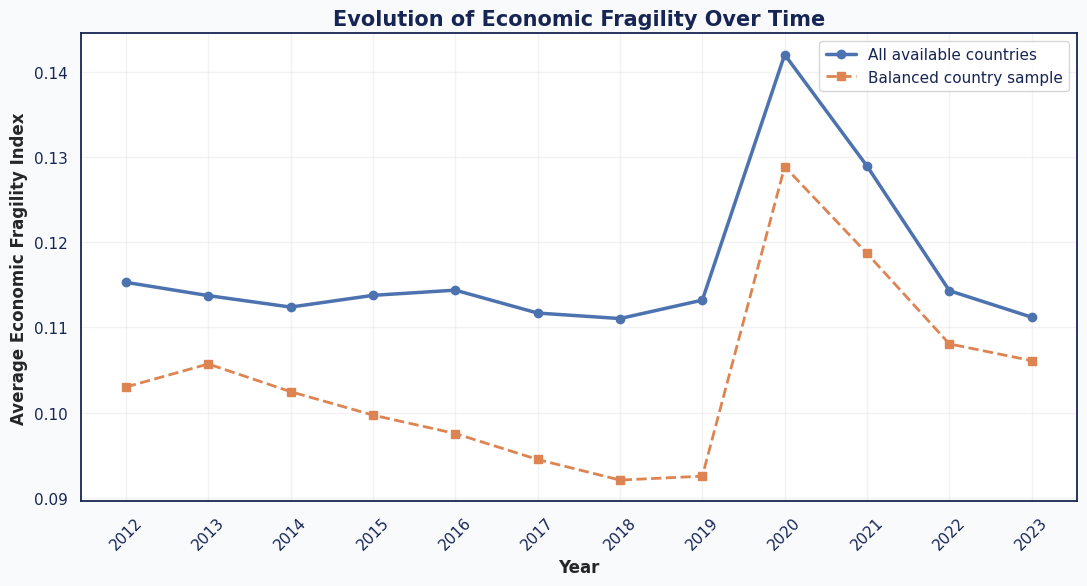

In [30]:

temporal_df = df[df["EFI"].notna()].copy()

annual_analysis = (
    temporal_df.groupby("year")
    .agg(
        Valid_Countries=("country_name", "nunique"),
        Average_EFI=("EFI", "mean"),
        Median_EFI=("EFI", "median"),
        Std_EFI=("EFI", "std"),
        Minimum_EFI=("EFI", "min"),
        Maximum_EFI=("EFI", "max")
    )
    .reset_index()
)

annual_analysis["Annual_Change"] = annual_analysis["Average_EFI"].diff()

print("ANNUAL EFI ANALYSIS")
display(annual_analysis.round(6))

print("\nHIGHEST AVERAGE EFI YEAR")
display(annual_analysis.nlargest(1, "Average_EFI"))

print("\nLOWEST AVERAGE EFI YEAR")
display(annual_analysis.nsmallest(1, "Average_EFI"))

years = sorted(temporal_df["year"].unique())

country_year_coverage = temporal_df.groupby("country_name")["year"].nunique()
balanced_countries = country_year_coverage[country_year_coverage == len(years)].index

balanced_df = temporal_df[temporal_df["country_name"].isin(balanced_countries)].copy()

balanced_analysis = (
    balanced_df.groupby("year")
    .agg(Average_EFI=("EFI", "mean"), Valid_Countries=("country_name", "nunique"))
    .reset_index()
)

print("\nBALANCED PANEL COUNTRIES:", len(balanced_countries))
print("\nBALANCED PANEL RESULTS")
display(balanced_analysis.round(6))

plt.figure(figsize=(11, 6))

plt.plot(
    annual_analysis["year"], annual_analysis["Average_EFI"],
    marker="o", linewidth=2.5, label="All available countries"
)

if len(balanced_countries) > 0:
    plt.plot(
        balanced_analysis["year"], balanced_analysis["Average_EFI"],
        marker="s", linestyle="--", linewidth=2,
        label="Balanced country sample"
    )

plt.title("Evolution of Economic Fragility Over Time", fontsize=15, fontweight="bold")
plt.xlabel("Year", fontsize=12)
plt.ylabel("Average Economic Fragility Index", fontsize=12)
plt.xticks(years, rotation=45)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

plt.savefig("EFI_Temporal_Analysis.png", dpi=300, bbox_inches="tight")
plt.show()


LARGEST INCREASES IN EFI


,country_name,EFI_2012,EFI_2013,EFI_2014,EFI_2015,EFI_2016,EFI_2017,EFI_2018,EFI_2019,EFI_2020,EFI_2021,EFI_2022,EFI_2023,Absolute_Change,Percentage_Change
1,"Bahamas, The",0.119705,0.150917,0.118806,0.115722,0.114072,0.123644,0.118898,0.107768,0.157952,0.186810,0.224342,0.209724,0.090019,75.200224
3,Brazil,0.083159,0.085462,0.093973,0.116126,0.127564,0.145369,0.145256,0.145134,0.183198,0.145271,0.123535,0.134882,0.051723,62.197875
27,Uruguay,0.068581,0.069933,0.074328,0.081882,0.083677,0.082415,0.081032,0.091533,0.113691,0.110214,0.118454,0.117236,0.048655,70.944118
20,Singapore,0.104712,0.098102,0.096709,0.092942,0.097013,0.098589,0.096690,0.107438,0.157376,0.134760,0.136076,0.149196,0.044484,42.482164
18,Moldova,0.047332,0.044784,0.046603,0.049649,0.051627,0.045617,0.042360,0.043134,0.065974,0.055389,0.073621,0.083043,0.035711,75.447494
8,El Salvador,0.093236,0.101418,0.095591,0.095322,0.090411,0.087054,0.084175,0.086955,0.138496,0.106297,0.105798,0.125321,0.032084,34.411957
23,Thailand,0.033136,0.037485,0.036127,0.035647,0.036234,0.035355,0.035632,0.035648,0.061573,0.078963,0.069862,0.059546,0.026410,79.700338
17,Malaysia,0.058837,0.060495,0.058522,0.058970,0.059363,0.058559,0.059412,0.061400,0.089016,0.088419,0.082023,0.079794,0.020957,35.618708
24,Turkiye,0.063816,0.058595,0.059067,0.058876,0.060626,0.068687,0.072129,0.095649,0.091591,0.081185,0.091401,0.084555,0.020739,32.497587
15,"Korea, Rep.",0.048456,0.050638,0.052929,0.053441,0.053470,0.053234,0.057803,0.056514,0.071233,0.068223,0.068499,0.064230,0.015774,32.552438



LARGEST DECREASES IN EFI


,country_name,EFI_2012,EFI_2013,EFI_2014,EFI_2015,EFI_2016,EFI_2017,EFI_2018,EFI_2019,EFI_2020,EFI_2021,EFI_2022,EFI_2023,Absolute_Change,Percentage_Change
13,Iceland,0.165320,0.144913,0.134782,0.118685,0.103161,0.097324,0.090466,0.100248,0.143897,0.144271,0.120399,0.105471,-0.059849,-36.201834
12,Greece,0.255105,0.296113,0.257165,0.251362,0.227243,0.219460,0.220852,0.217349,0.279873,0.258704,0.217905,0.197210,-0.057895,-22.694492
2,Bosnia and Herzegovina,0.133372,0.132698,0.135771,0.134841,0.127252,0.107519,0.099933,0.089210,0.097616,0.095914,0.088707,0.079491,-0.053881,-40.398972
16,Lithuania,0.107424,0.094816,0.087911,0.075668,0.066280,0.059488,0.051995,0.055392,0.089923,0.068792,0.059802,0.057260,-0.050164,-46.697119
21,Spain,0.180698,0.177070,0.176726,0.166949,0.161682,0.149835,0.140632,0.140624,0.196576,0.181097,0.152504,0.143780,-0.036917,-20.430328
7,Croatia,0.130190,0.140181,0.145305,0.137126,0.119356,0.104697,0.094154,0.083445,0.124003,0.110540,0.101359,0.101079,-0.029111,-22.360585
25,United Kingdom,0.167432,0.151513,0.150431,0.142114,0.139528,0.139375,0.138405,0.137007,0.210107,0.187733,0.143161,0.144441,-0.022990,-13.731116
4,Bulgaria,0.061659,0.064768,0.080227,0.059284,0.055237,0.048932,0.042997,0.037938,0.059152,0.064459,0.059030,0.050007,-0.011651,-18.896752
14,Kazakhstan,0.091075,0.106141,0.103770,0.098678,0.089484,0.093102,0.093715,0.090768,0.101073,0.095891,0.082582,0.083031,-0.008043,-8.831436
0,Austria,0.101503,0.099836,0.106087,0.101201,0.104558,0.096415,0.088390,0.084807,0.129923,0.123000,0.099643,0.096965,-0.004538,-4.470421



COUNTRY-LEVEL CHANGE SUMMARY


,Absolute_Change,Percentage_Change
count,28.000000,28.000000
mean,0.003092,12.544372
std,0.035776,36.683253
min,-0.059849,-46.697119
25%,-0.014486,-15.022525
50%,0.004558,4.534095
75%,0.022320,34.713645
max,0.090019,79.700338



NUMBER OF COUNTRIES: 28


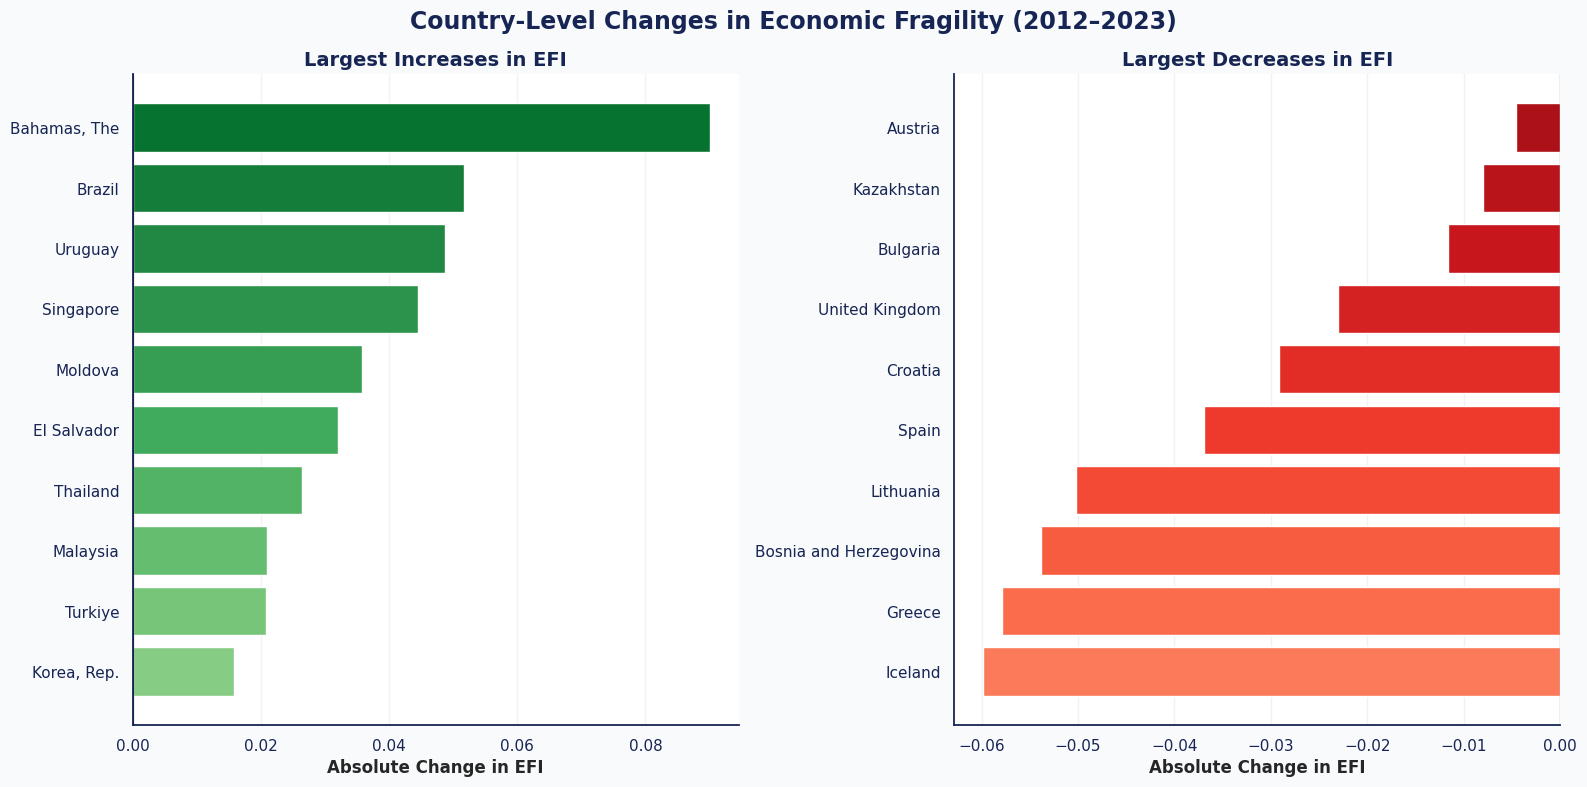

In [31]:

years = list(range(2012, 2024))

temporal_df = df[df["EFI"].notna() & df["year"].isin(years)].copy()

country_coverage = temporal_df.groupby("country_name")["year"].nunique()
balanced_countries = country_coverage[country_coverage == len(years)].index

balanced_df = temporal_df[temporal_df["country_name"].isin(balanced_countries)].copy()

if balanced_df.duplicated(["country_name", "year"]).any():
    raise ValueError("Duplicate country-year observations found.")

country_changes = balanced_df.pivot(index="country_name", columns="year", values="EFI")
country_changes = country_changes.reindex(columns=years).dropna().reset_index()
country_changes.columns = ["country_name"] + [f"EFI_{year}" for year in years]

country_changes["Absolute_Change"] = country_changes["EFI_2023"] - country_changes["EFI_2012"]

country_changes["Percentage_Change"] = (
    country_changes["Absolute_Change"] / country_changes["EFI_2012"].replace(0, np.nan)
) * 100

largest_increases = country_changes.nlargest(10, "Absolute_Change")
largest_decreases = country_changes.nsmallest(10, "Absolute_Change")

print("LARGEST INCREASES IN EFI")
display(largest_increases.round(6))

print("\nLARGEST DECREASES IN EFI")
display(largest_decreases.round(6))

print("\nCOUNTRY-LEVEL CHANGE SUMMARY")
display(country_changes[["Absolute_Change", "Percentage_Change"]].describe().round(6))

print("\nNUMBER OF COUNTRIES:", len(country_changes))

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

increase_plot = largest_increases.sort_values("Absolute_Change")
decrease_plot = largest_decreases.sort_values("Absolute_Change")

axes[0].barh(
    increase_plot["country_name"], increase_plot["Absolute_Change"],
    color=plt.cm.Greens(np.linspace(0.45, 0.85, len(increase_plot)))
)
axes[0].set_title("Largest Increases in EFI", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Absolute Change in EFI")
axes[0].grid(axis="x", alpha=0.25)

axes[1].barh(
    decrease_plot["country_name"], decrease_plot["Absolute_Change"],
    color=plt.cm.Reds(np.linspace(0.45, 0.85, len(decrease_plot)))
)
axes[1].set_title("Largest Decreases in EFI", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Absolute Change in EFI")
axes[1].grid(axis="x", alpha=0.25)

fig.suptitle("Country-Level Changes in Economic Fragility (2012–2023)", fontsize=17, fontweight="bold")

for ax in axes:
    ax.axvline(0, color="black", linewidth=0.8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("Country_Level_EFI_Changes.png", dpi=300, bbox_inches="tight")
plt.show()


In [32]:

valid_efi = df[df["EFI"].notna()].copy()

Q1, Q2, Q3 = valid_efi["EFI"].quantile([0.25, 0.50, 0.75])

bins = [-np.inf, Q1, Q2, Q3, np.inf]
labels = ["Low Fragility", "Moderate Fragility", "High Fragility", "Critical Fragility"]

valid_efi["EFI_Category"] = pd.cut(
    valid_efi["EFI"], bins=bins, labels=labels, include_lowest=True
)

df["EFI_Category"] = pd.NA
df.loc[valid_efi.index, "EFI_Category"] = valid_efi["EFI_Category"].astype(str)

print("Q1 (25th percentile):", Q1)
print("Q2 (50th percentile):", Q2)
print("Q3 (75th percentile):", Q3)

classification_table = pd.DataFrame({
    "Category": labels,
    "Number of Observations": [(valid_efi["EFI_Category"] == category).sum() for category in labels]
})

classification_table["Percentage"] = classification_table["Number of Observations"] / len(valid_efi) * 100

print("\nCLASSIFICATION SUMMARY")
display(classification_table)

print("\nTotal classified observations:", len(valid_efi))
print("Missing EFI observations:", df["EFI"].isna().sum())

print("\nCLASSIFIED OBSERVATIONS")
display(valid_efi[["country_name", "year", "EFI", "EFI_Category"]].head(15))


Q1 (25th percentile): 0.07981125723849909
Q2 (50th percentile): 0.10705592795954938
Q3 (75th percentile): 0.14553932669089562

CLASSIFICATION SUMMARY


,Category,Number of Observations,Percentage
0,Low Fragility,179,25.070028
1,Moderate Fragility,178,24.929972
2,High Fragility,178,24.929972
3,Critical Fragility,179,25.070028



Total classified observations: 714
Missing EFI observations: 2237

CLASSIFIED OBSERVATIONS


,country_name,year,EFI,EFI_Category
47,Albania,2012,0.135217,High Fragility
48,Albania,2013,0.153116,Critical Fragility
49,Albania,2014,0.153842,Critical Fragility
50,Albania,2015,0.148451,Critical Fragility
51,Albania,2016,0.147020,Critical Fragility
52,Albania,2017,0.138041,High Fragility
53,Albania,2018,0.122228,High Fragility
54,Albania,2019,0.123350,High Fragility
55,Albania,2020,0.135681,High Fragility
56,Albania,2021,0.131116,High Fragility


Machine Learning

In [ ]:

print("Dataset shape:", df.shape)

print("\nAvailable columns:")
print(df.columns.tolist())

print("\nValid EFI observations:")
print(df["EFI"].notna().sum())

print("\nValid classifications:")
print(df["EFI_Category"].notna().sum())

Dataset shape: (2951, 41)

Available columns:
['year', 'country_iso3', 'country_name', 'country_id', 'Interest Rate (Real, %)', 'Public Debt (% of GDP)', 'exports_usd', 'imports_usd', 'trade_balance_usd', 'export_partner_hhi', 'export_product_hhi', 'momentum_score', 'risk_score', 'Inflation (CPI %)', 'GDP (Current USD)', 'GDP per Capita (Current USD)', 'Unemployment Rate (%)', 'Inflation (GDP Deflator, %)', 'GDP Growth (% Annual)', 'Current Account Balance (% GDP)', 'Government Expense (% of GDP)', 'Government Revenue (% of GDP)', 'Tax Revenue (% of GDP)', 'Gross National Income (USD)', 'Public Debt (% of GDP)_imputed', 'Interest Rate (Real, %)_imputed', 'GDP Growth Volatility', 'Fiscal Balance', 'Fiscal Deficit', 'Partner_HHI_Norm', 'Product_HHI_Norm', 'GDP_Volatility_Norm', 'Inflation_Norm', 'Unemployment_Norm', 'Public_Debt_Norm', 'Fiscal_Deficit_Norm', 'Trade_Vulnerability', 'Macroeconomic_Instability', 'Fiscal_Vulnerability', 'EFI', 'EFI_Category']

Valid EFI observations:
714

Va

In [33]:

df_ml = df[df["EFI"].notna() & df["EFI_Category"].notna()].copy()

gdp = df_ml["GDP (Current USD)"].replace(0, np.nan)

df_ml["Trade_Openness_GDP"] = ((df_ml["exports_usd"] + df_ml["imports_usd"]) / gdp) * 100
df_ml["Trade_Balance_GDP"] = (df_ml["trade_balance_usd"] / gdp) * 100

features = [
    "Trade_Openness_GDP", "Trade_Balance_GDP",
    "Current Account Balance (% GDP)", "GDP per Capita (Current USD)", "year"
]

target = "EFI_Category"

print("ML DATASET SHAPE:", df_ml.shape)

print("\nINPUT FEATURES:")
print(features)

print("\nTARGET VARIABLE:", target)

print("\nMISSING VALUES:")
print(df_ml[features].isnull().sum())

print("\nMISSING VALUES (%):")
print((df_ml[features].isnull().mean() * 100).round(2))

print("\nCLASS DISTRIBUTION:")
print(df_ml[target].value_counts())

print("\nNUMBER OF COUNTRIES:", df_ml["country_name"].nunique())


ML DATASET SHAPE: (714, 43)

INPUT FEATURES:
['Trade_Openness_GDP', 'Trade_Balance_GDP', 'Current Account Balance (% GDP)', 'GDP per Capita (Current USD)', 'year']

TARGET VARIABLE: EFI_Category

MISSING VALUES:
Trade_Openness_GDP                 0
Trade_Balance_GDP                  0
Current Account Balance (% GDP)    0
GDP per Capita (Current USD)       0
year                               0
dtype: int64

MISSING VALUES (%):
Trade_Openness_GDP                 0.0
Trade_Balance_GDP                  0.0
Current Account Balance (% GDP)    0.0
GDP per Capita (Current USD)       0.0
year                               0.0
dtype: float64

CLASS DISTRIBUTION:
EFI_Category
Critical Fragility    179
Low Fragility         179
High Fragility        178
Moderate Fragility    178
Name: count, dtype: int64

NUMBER OF COUNTRIES: 81


In [ ]:
X = df_ml[features].copy()

y = df_ml["EFI_Category"].copy()

print("INPUT DATA SHAPE:", X.shape)
print("TARGET DATA SHAPE:", y.shape)

print("\nINPUT VARIABLES:")
print(X.head())
print("\nTARGET VARIABLE:")
print(y.head())

print("\nTARGET DISTRIBUTION:")
print(y.value_counts())


INPUT DATA SHAPE: (714, 5)
TARGET DATA SHAPE: (714,)

INPUT VARIABLES:
    Trade_Openness_GDP  Trade_Balance_GDP  Current Account Balance (% GDP)  \
47           53.363936         -20.497329                       -10.200176   
48           55.021648         -16.611949                        -9.274188   
49           56.019580         -18.035905                       -10.775399   
50           53.318958         -19.015766                        -8.604880   
51           54.339936         -20.649689                        -7.590826   

    GDP per Capita (Current USD)  year  
47                   4247.631343  2012  
48                   4413.063383  2013  
49                   4578.633208  2014  
50                   3952.803574  2015  
51                   4124.055390  2016  

TARGET VARIABLE:
47        High Fragility
48    Critical Fragility
49    Critical Fragility
50    Critical Fragility
51    Critical Fragility
Name: EFI_Category, dtype: object

TARGET DISTRIBUTION:
EFI_Category
Cr

In [ ]:
print("FEATURE DATA TYPES:")
print(X.dtypes)

print("\nFEATURE STATISTICS:")
print(X.describe().T)

print("\nMISSING VALUES:")
print(X.isnull().sum())

print("\nDUPLICATED COUNTRY-YEAR RECORDS:")
print(df_ml.duplicated(
    subset=["country_name", "year"]
).sum())
print("\nNUMBER OF COUNTRIES:")
print(df_ml["country_name"].nunique())



FEATURE DATA TYPES:
Trade_Openness_GDP                 float64
Trade_Balance_GDP                  float64
Current Account Balance (% GDP)    float64
GDP per Capita (Current USD)       float64
year                                 int64
dtype: object

FEATURE STATISTICS:
                                 count          mean           std  \
Trade_Openness_GDP               714.0    157.407346    811.461157   
Trade_Balance_GDP                714.0    -86.434830    739.993917   
Current Account Balance (% GDP)  714.0     -2.305395      7.918140   
GDP per Capita (Current USD)     714.0  20224.049256  22096.251683   
year                             714.0   2017.141457      3.297054   

                                         min          25%           50%  \
Trade_Openness_GDP                 16.642513    43.181588     64.884749   
Trade_Balance_GDP               -8764.552798   -16.522147     -4.375906   
Current Account Balance (% GDP)   -59.995551    -5.677041     -2.127728   
GDP per C

In [ ]:
from IPython.display import display
import pandas as pd
quality_table = pd.DataFrame({
    "Assessment": [
        "Total observations",
        "Number of countries",
        "Number of input features",
        "Missing values",
        "Duplicate country-year records",
        "Numerical input variables"
    ],
    "Result": [
        714, 81, 5, 0, 0, 5
    ]
})

display(quality_table)

,Assessment,Result
0,Total observations,714
1,Number of countries,81
2,Number of input features,5
3,Missing values,0
4,Duplicate country-year records,0
5,Numerical input variables,5


In [ ]:
statistics_table = X.describe().T[
    ["mean", "std", "min", "50%", "max"]
]

statistics_table.columns = [
    "Mean", "Standard Deviation",
    "Minimum", "Median", "Maximum"
]

display(statistics_table.round(2))

,Mean,Standard Deviation,Minimum,Median,Maximum
Trade_Openness_GDP,157.41,811.46,16.64,64.88,9405.85
Trade_Balance_GDP,-86.43,739.99,-8764.55,-4.38,29.44
Current Account Balance (% GDP),-2.31,7.92,-60.00,-2.13,36.98
GDP per Capita (Current USD),20224.05,22096.25,441.49,10197.33,106194.76
year,2017.14,3.30,2012.00,2017.00,2023.00


In [ ]:

from sklearn.model_selection import StratifiedGroupKFold
import pandas as pd

groups = df_ml.loc[X.index, "country_name"]


sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    sgkf.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

print("TRAINING DATA:", X_train.shape)
print("TESTING DATA:", X_test.shape)

print("\nTRAINING OBSERVATIONS:", len(X_train))
print("TESTING OBSERVATIONS:", len(X_test))

train_countries = groups.iloc[train_idx]
test_countries = groups.iloc[test_idx]

print("\nCOUNTRIES IN TRAINING:", train_countries.nunique())
print("COUNTRIES IN TESTING:", test_countries.nunique())

overlap = set(train_countries) & set(test_countries)

print("\nCOUNTRIES IN BOTH SETS:", len(overlap))

print("\nTRAINING CLASS DISTRIBUTION:")
print(y_train.value_counts())

print("\nTESTING CLASS DISTRIBUTION:")
print(y_test.value_counts())


TRAINING DATA: (573, 5)
TESTING DATA: (141, 5)

TRAINING OBSERVATIONS: 573
TESTING OBSERVATIONS: 141

COUNTRIES IN TRAINING: 66
COUNTRIES IN TESTING: 15

COUNTRIES IN BOTH SETS: 0

TRAINING CLASS DISTRIBUTION:
EFI_Category
Moderate Fragility    147
Low Fragility         144
Critical Fragility    142
High Fragility        140
Name: count, dtype: int64

TESTING CLASS DISTRIBUTION:
EFI_Category
High Fragility        38
Critical Fragility    37
Low Fragility         35
Moderate Fragility    31
Name: count, dtype: int64


In [ ]:

from IPython.display import display
import pandas as pd

split_summary = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "Observations": [len(X_train), len(X_test)],
    "Percentage (%)": [
        len(X_train) / len(X) * 100,
        len(X_test) / len(X) * 100
    ],
    "Countries": [
        train_countries.nunique(),
        test_countries.nunique()
    ]
})

print("TABLE 6.3 - TRAINING AND TESTING DATA")
display(
    split_summary.style
    .hide(axis="index")
    .format({"Percentage (%)": "{:.2f}"})
)

categories = [
    "Low Fragility",
    "Moderate Fragility",
    "High Fragility",
    "Critical Fragility"
]

class_summary = pd.DataFrame({
    "Category": categories,
    "Training Observations": [
        (y_train == c).sum() for c in categories
    ],
    "Training (%)": [
        (y_train == c).mean() * 100 for c in categories
    ],
    "Testing Observations": [
        (y_test == c).sum() for c in categories
    ],
    "Testing (%)": [
        (y_test == c).mean() * 100 for c in categories
    ]
})

print("\nTABLE 6.4 - CLASS DISTRIBUTION")
display(
    class_summary.style
    .hide(axis="index")
    .format({
        "Training (%)": "{:.2f}",
        "Testing (%)": "{:.2f}"
    })
)


TABLE 6.3 - TRAINING AND TESTING DATA


Dataset,Observations,Percentage (%),Countries
Training,573,80.25,66
Testing,141,19.75,15



TABLE 6.4 - CLASS DISTRIBUTION


Category,Training Observations,Training (%),Testing Observations,Testing (%)
Low Fragility,144,25.13,35,24.82
Moderate Fragility,147,25.65,31,21.99
High Fragility,140,24.43,38,26.95
Critical Fragility,142,24.78,37,26.24


In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier

models = {"Logistic Regression": Pipeline([("scaler", RobustScaler()),("model", LogisticRegression(max_iter=5000, random_state=42))]),
          "K-Nearest Neighbors": Pipeline([("scaler", RobustScaler()),("model", KNeighborsClassifier(n_neighbors=5))]),
          "Decision Tree": DecisionTreeClassifier(random_state=42),
          "Random Forest": RandomForestClassifier(n_estimators=300,random_state=42,n_jobs=-1),
          "Support Vector Machine": Pipeline([("scaler", RobustScaler()),("model", SVC(kernel="rbf", C=1))]),
          "Gradient Boosting": GradientBoostingClassifier(n_estimators=100,learning_rate=0.1,max_depth=3,random_state=42)}

for name, model in models.items():
  model.fit(X_train, y_train)
  print(name, "successfully trained")

print("\nTOTAL TRAINED MODELS:", len(models))


Logistic Regression successfully trained
K-Nearest Neighbors successfully trained
Decision Tree successfully trained
Random Forest successfully trained
Support Vector Machine successfully trained
Gradient Boosting successfully trained

TOTAL TRAINED MODELS: 6


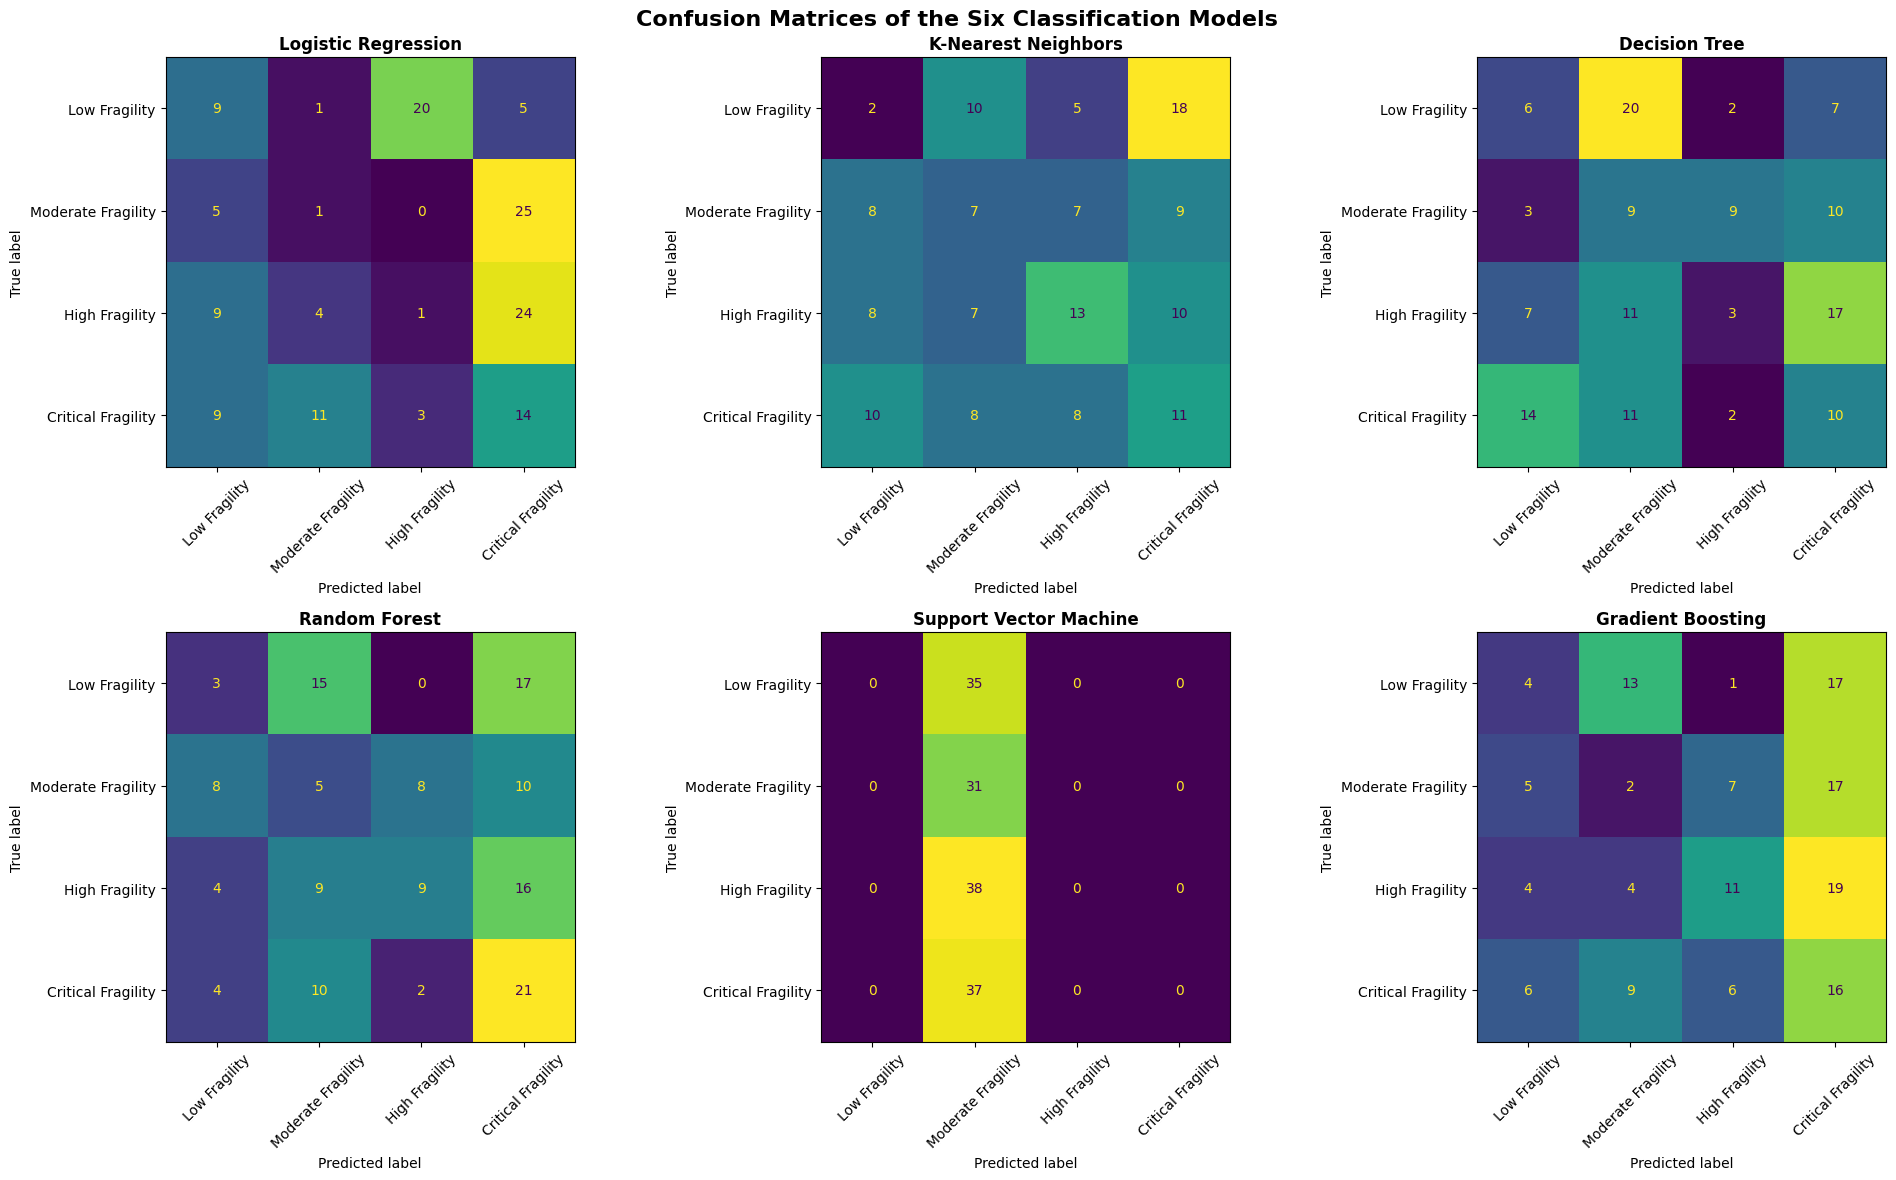

In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(2, 3, figsize=(20, 12))

for (name, y_pred), ax in zip(
    predictions.items(),
    axes.flatten()
):
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=categories
    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=categories
    )

    display_matrix.plot(
        ax=ax,
        xticks_rotation=45,
        colorbar=False,
        values_format="d"
    )

    ax.set_title(name, fontsize=12, fontweight="bold")

plt.suptitle(
    "Confusion Matrices of the Six Classification Models",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


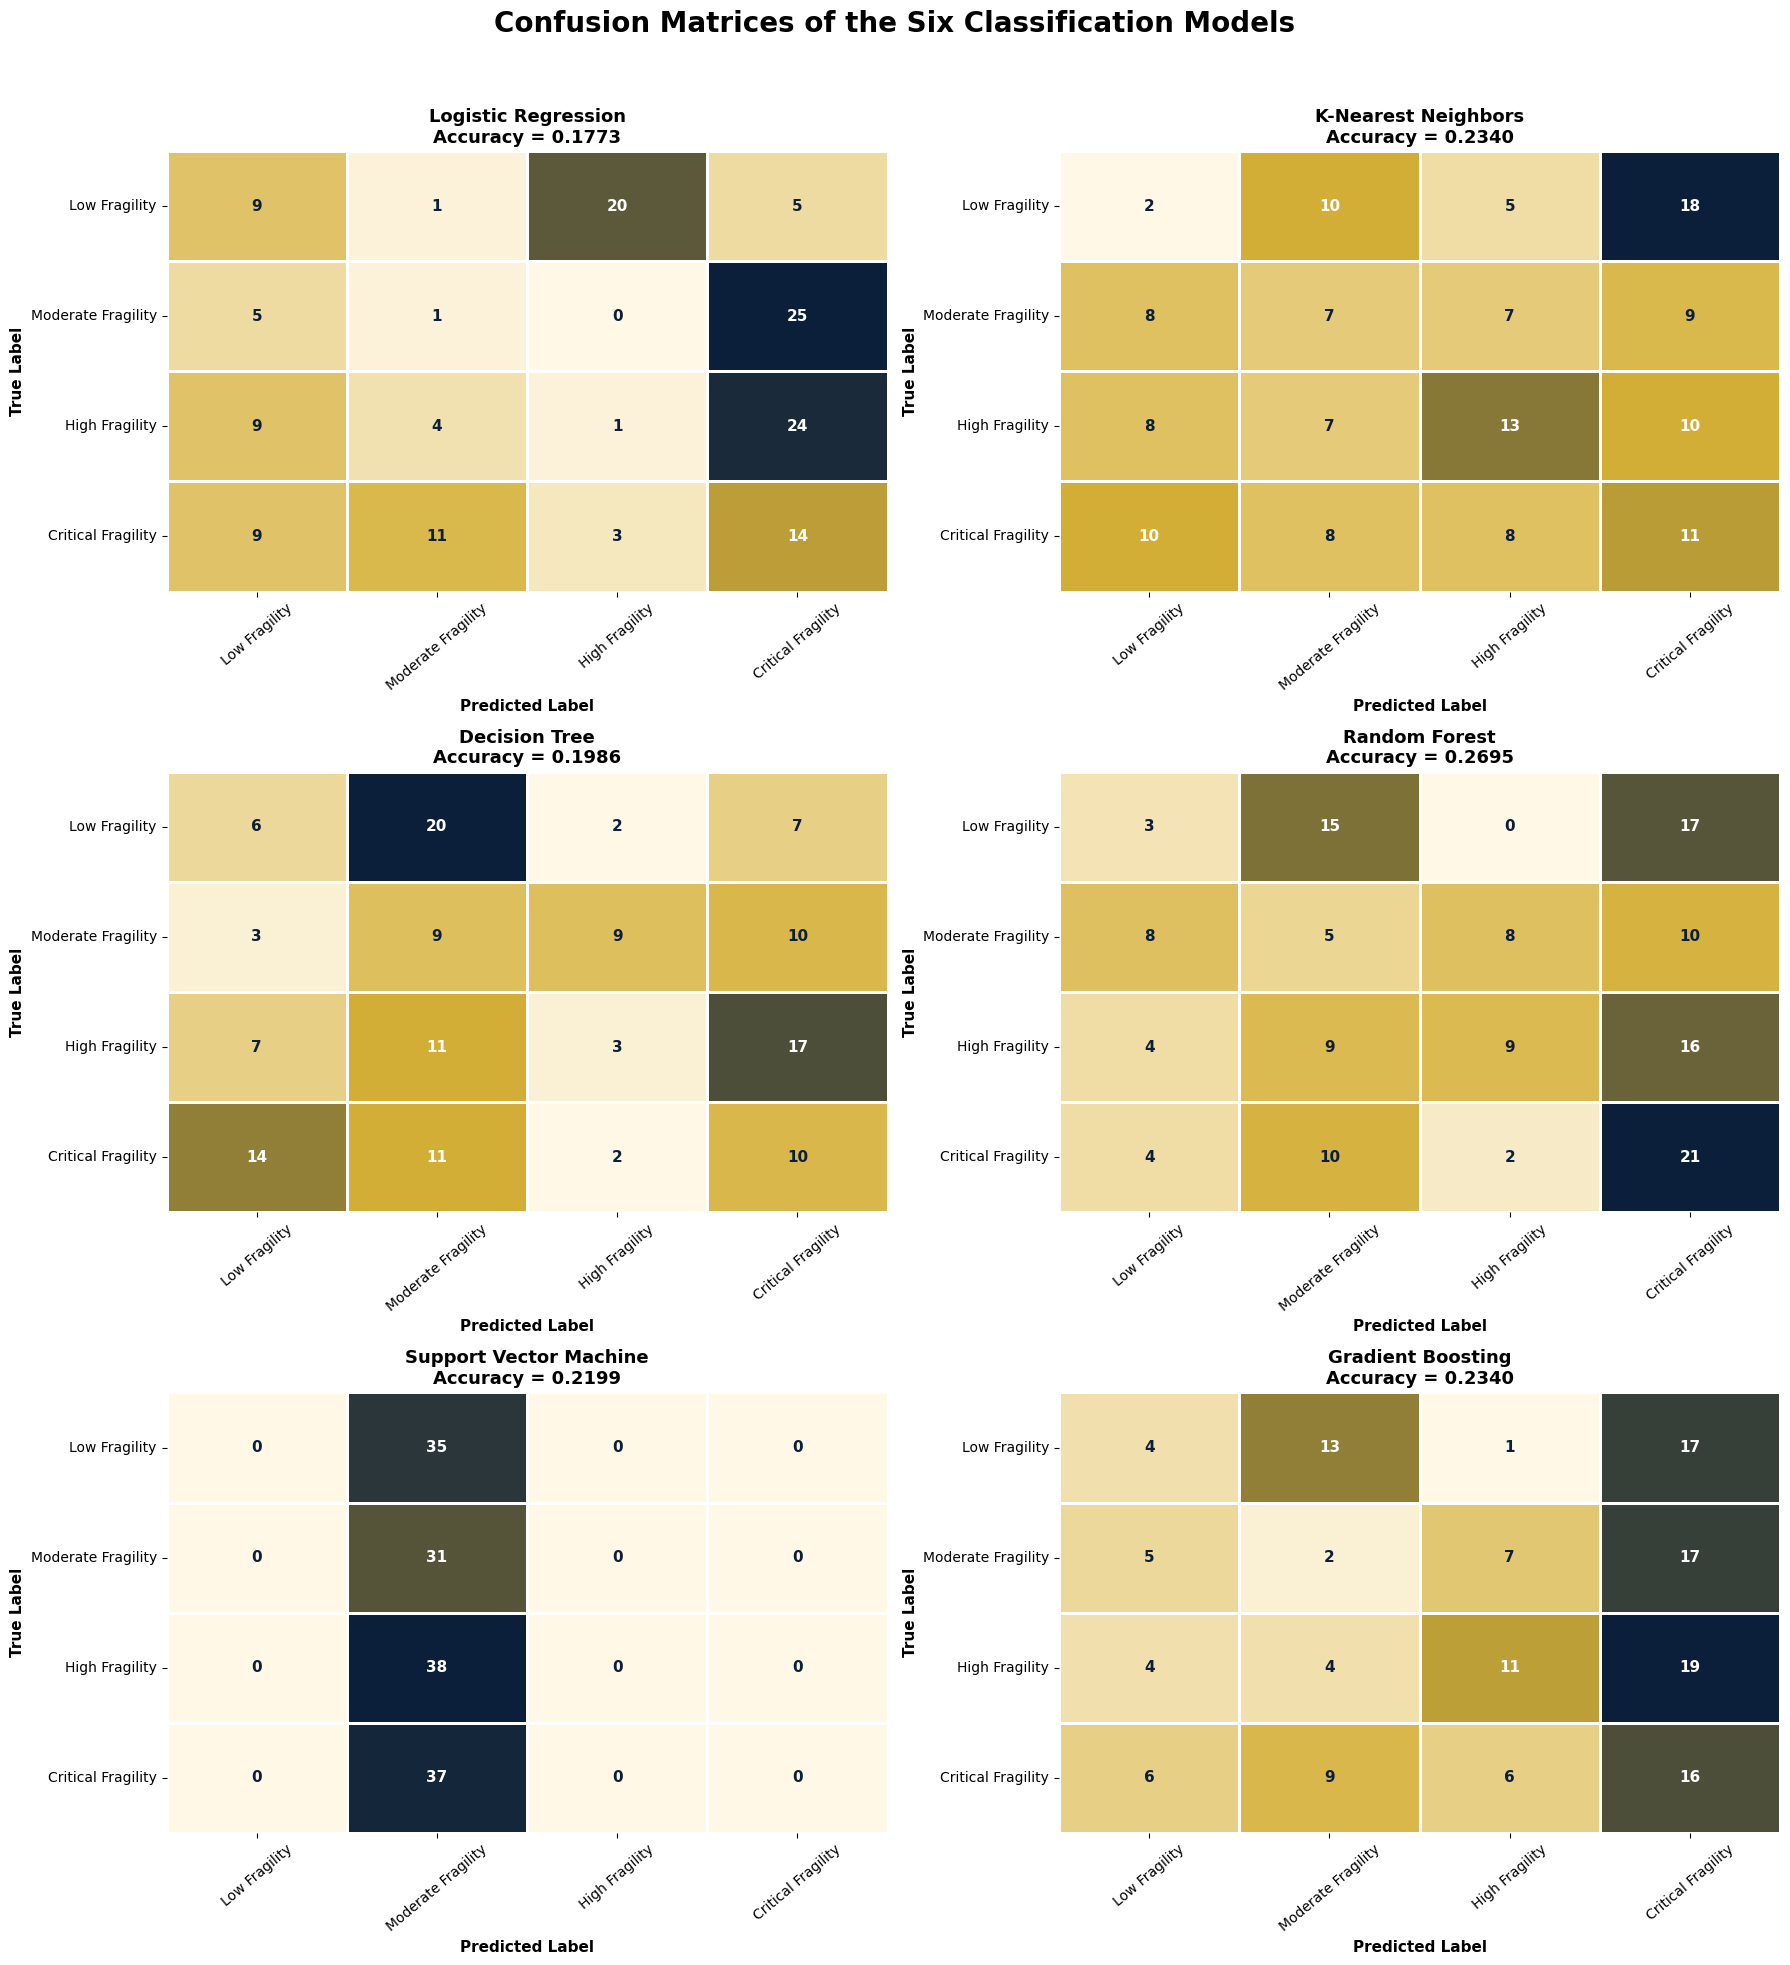

In [ ]:
# ==========================================
# ELEGANT VERSION WITH DYNAMIC TEXT COLORS
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, accuracy_score
from matplotlib.colors import LinearSegmentedColormap

class_names = [
    "Low Fragility",
    "Moderate Fragility",
    "High Fragility",
    "Critical Fragility"
]

navy_gold_cmap = LinearSegmentedColormap.from_list(
    "navy_gold",
    ["#FFF8E7", "#D4AF37", "#0B1F3A"]
)

fig, axes = plt.subplots(3, 2, figsize=(18, 20))
axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):

    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred, labels=class_names)
    acc = accuracy_score(y_test, y_pred)

    ax = axes[i]

    heatmap = sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap=navy_gold_cmap,
        cbar=False,
        linewidths=1,
        linecolor="white",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax,
        annot_kws={"size": 11, "weight": "bold"}
    )

    ax.set_title(f"{name}\nAccuracy = {acc:.4f}", fontsize=13, fontweight="bold")
    ax.set_xlabel("Predicted Label", fontsize=11, fontweight="bold")
    ax.set_ylabel("True Label", fontsize=11, fontweight="bold")
    ax.tick_params(axis='x', rotation=40)
    ax.tick_params(axis='y', rotation=0)

    # Make annotation text color dynamic
    threshold = cm.max() / 2.0
    for text in ax.texts:
        value = int(text.get_text())
        if value > threshold:
            text.set_color("white")
        else:
            text.set_color("#0B1F3A")

plt.suptitle(
    "Confusion Matrices of the Six Classification Models",
    fontsize=20,
    fontweight="bold",
    y=0.98
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("Figure_6_2_Confusion_Matrices_Six_Models_Navy_Gold.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:

from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
baseline_accuracy = accuracy_score(
    y_test, baseline_pred
)

baseline_f1 = f1_score(
    y_test, baseline_pred,
    average="macro"
)
print("MOST FREQUENT CATEGORY:",
      baseline.classes_[0])

print("BASELINE ACCURACY:",
      round(baseline_accuracy, 4))

print("BASELINE MACRO F1:",
      round(baseline_f1, 4))


MOST FREQUENT CATEGORY: Critical Fragility
BASELINE ACCURACY: 0.2199
BASELINE MACRO F1: 0.0901


RANDOM FOREST FEATURE IMPORTANCE


Feature,Importance
Trade_Openness_GDP,0.2454
GDP per Capita (Current USD),0.2391
Trade_Balance_GDP,0.2289
Current Account Balance (% GDP),0.1793
year,0.1073


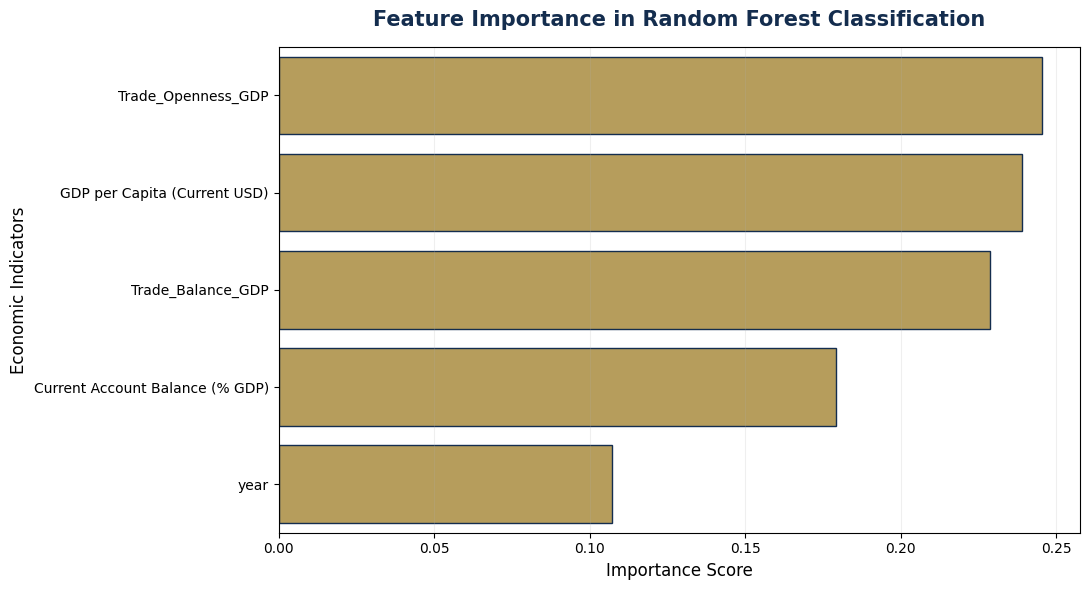

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
rf_model = models["Random Forest"]

importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)
print("RANDOM FOREST FEATURE IMPORTANCE")

display(
    importance_df.style
    .hide(axis="index")
    .format({"Importance": "{:.4f}"})
)
navy = "#142D4E"
gold = "#C5A44D"
plt.figure(figsize=(11, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature",
    color=gold,
    edgecolor=navy
)

plt.title(
    "Feature Importance in Random Forest Classification",
    fontsize=15,
    fontweight="bold",
    color=navy,
    pad=15
)

plt.xlabel("Importance Score", fontsize=12)
plt.ylabel("Economic Indicators", fontsize=12)

plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.savefig(
    "Figure_6_3_Feature_Importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


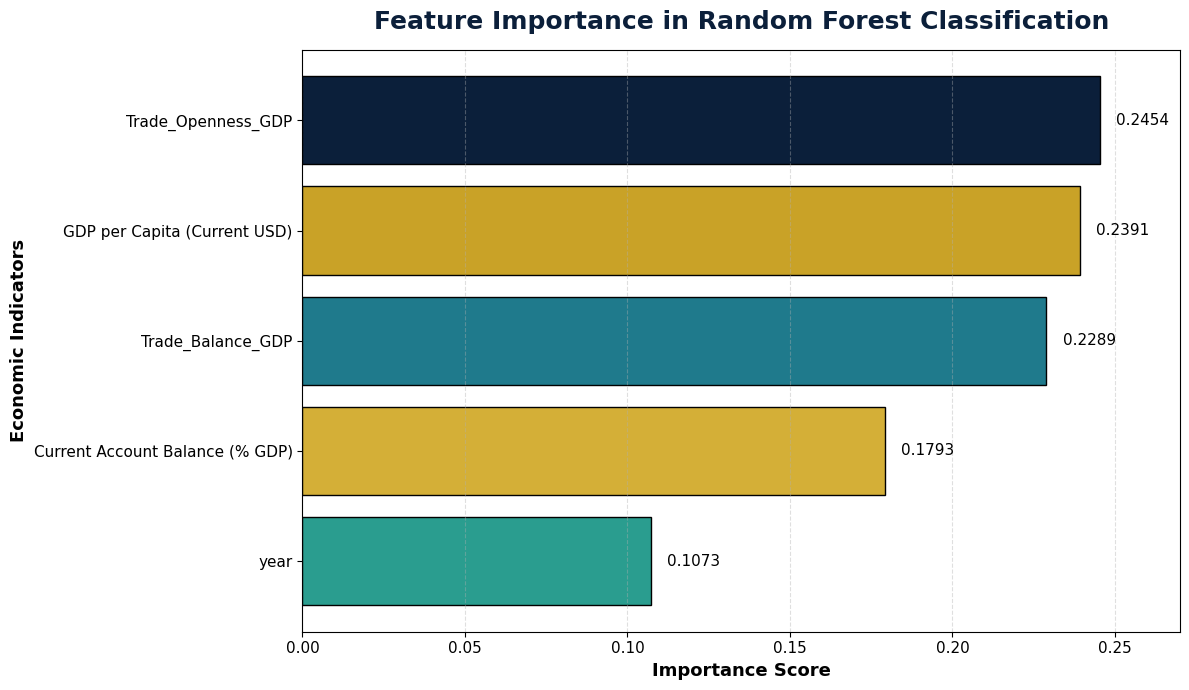

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
importance_df = pd.DataFrame({
    "Feature": [
        "Trade_Openness_GDP",
        "GDP per Capita (Current USD)",
        "Trade_Balance_GDP",
        "Current Account Balance (% GDP)",
        "year"
    ],
    "Importance": [0.2454, 0.2391, 0.2289, 0.1793, 0.1073]
})
importance_df = importance_df.iloc[::-1]

colors = [
    "#2A9D8F",  # soft teal-green
    "#D4AF37",  # lighter gold
    "#1F7A8C",  # teal
    "#C9A227",  # gold
    "#0B1F3A"   # deep navy
]

plt.figure(figsize=(12, 7))

bars = plt.barh(
    importance_df["Feature"],
    importance_df["Importance"],
    color=colors,
    edgecolor="black",
    linewidth=1.0
)

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.005,
        bar.get_y() + bar.get_height()/2,
        f"{width:.4f}",
        va="center",
        fontsize=11
    )

plt.title(
    "Feature Importance in Random Forest Classification",
    fontsize=18,
    fontweight="bold",
    color="#0B1F3A",
    pad=15
)

plt.xlabel("Importance Score", fontsize=13, fontweight="bold")
plt.ylabel("Economic Indicators", fontsize=13, fontweight="bold")
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.xlim(0, 0.27)

plt.tight_layout()
plt.savefig("Random_Forest_Feature_Importance_Navy_Gold_Teal.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:

!pip -q install shap

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
rf_model = models["Random Forest"]
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test)
if isinstance(shap_values, list):
    values = np.stack(shap_values, axis=-1)
else:
    values = np.asarray(shap_values)
if values.ndim == 3:
    importance = np.abs(values).mean(axis=(0, 2))
else:
    importance = np.abs(values).mean(axis=0)
shap_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean_Absolute_SHAP": importance
})

shap_importance = shap_importance.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
)

print("GLOBAL SHAP FEATURE IMPORTANCE")

display(shap_importance.style.hide(axis="index").format({
    "Mean_Absolute_SHAP": "{:.5f}"
}))


GLOBAL SHAP FEATURE IMPORTANCE


Feature,Mean_Absolute_SHAP
Trade_Openness_GDP,0.06219
GDP per Capita (Current USD),0.04649
Trade_Balance_GDP,0.04317
Current Account Balance (% GDP),0.02927
year,0.02280


In [ ]:

!pip -q install shap

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
rf_model = models["Random Forest"]
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test)
if isinstance(shap_values, list):
    values = np.stack(shap_values, axis=-1)
else:
    values = np.asarray(shap_values)
if values.ndim == 3:
    importance = np.abs(values).mean(axis=(0, 2))
else:
    importance = np.abs(values).mean(axis=0)
shap_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean_Absolute_SHAP": importance
})

shap_importance = shap_importance.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
)

print("GLOBAL SHAP FEATURE IMPORTANCE")

display(shap_importance.style.hide(axis="index").format({
    "Mean_Absolute_SHAP": "{:.5f}"
}))


GLOBAL SHAP FEATURE IMPORTANCE


Feature,Mean_Absolute_SHAP
Trade_Openness_GDP,0.06219
GDP per Capita (Current USD),0.04649
Trade_Balance_GDP,0.04317
Current Account Balance (% GDP),0.02927
year,0.02280


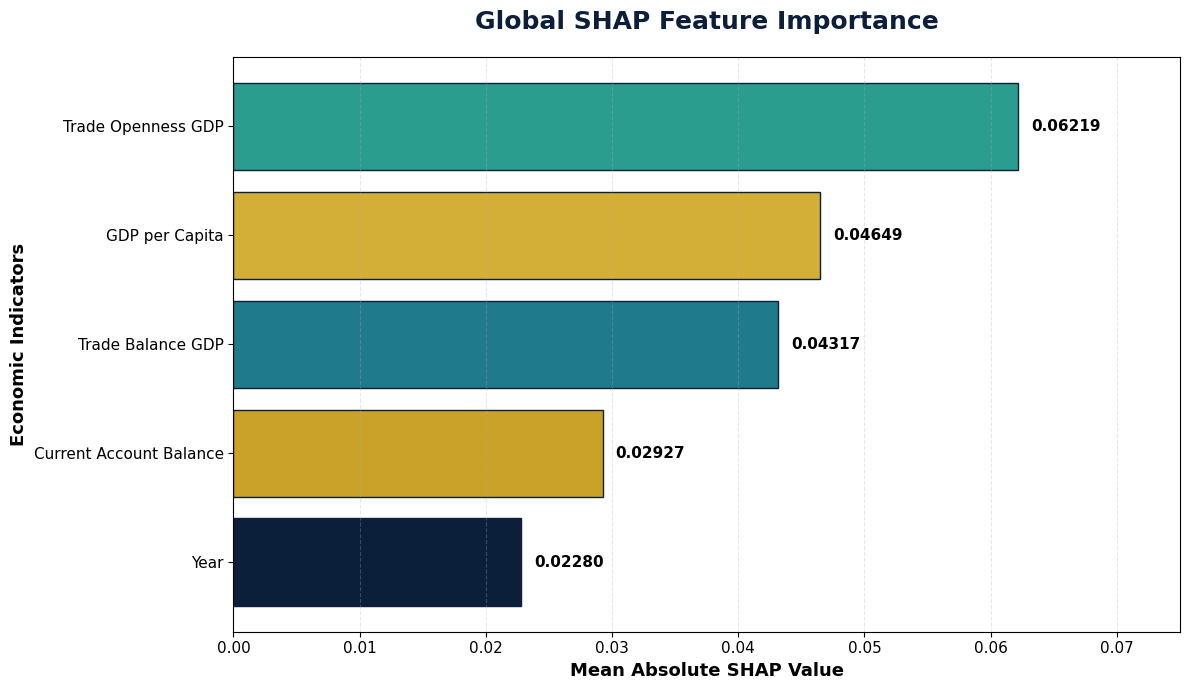

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

shap_df = pd.DataFrame({
    "Feature": [
        "Trade Openness GDP",
        "GDP per Capita",
        "Trade Balance GDP",
        "Current Account Balance",
        "Year"
    ],
    "Importance": [
        0.06219,
        0.04649,
        0.04317,
        0.02927,
        0.02280
    ]
})
shap_df = shap_df.sort_values(
    "Importance",
    ascending=True
)
colors = [
    "#0B1F3A",  # Navy
    "#C9A227",  # Gold
    "#1F7A8C",  # Teal
    "#D4AF37",  # Light Gold
    "#2A9D8F"   # Soft Teal
]
plt.figure(figsize=(12, 7))

bars = plt.barh(
    shap_df["Feature"],
    shap_df["Importance"],
    color=colors,
    edgecolor="#0B1F3A",
    linewidth=1
)
for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 0.001,
        bar.get_y() + bar.get_height()/2,
        f"{width:.5f}",
        va="center",
        fontsize=11,
        fontweight="bold"
    )
plt.title(
    "Global SHAP Feature Importance",
    fontsize=18,
    fontweight="bold",
    color="#0B1F3A",
    pad=20
)

plt.xlabel(
    "Mean Absolute SHAP Value",
    fontsize=13,
    fontweight="bold"
)

plt.ylabel(
    "Economic Indicators",
    fontsize=13,
    fontweight="bold"
)

plt.xlim(0, 0.075)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()
plt.savefig(
    "Global_SHAP_Feature_Importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


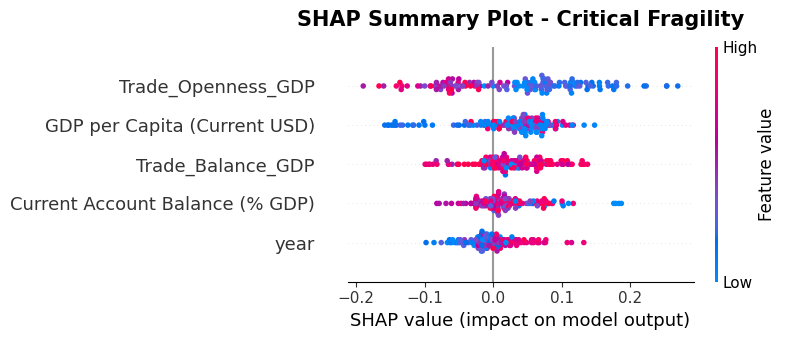

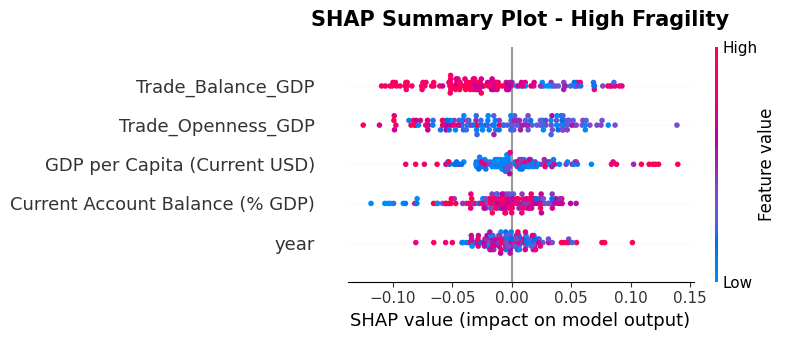

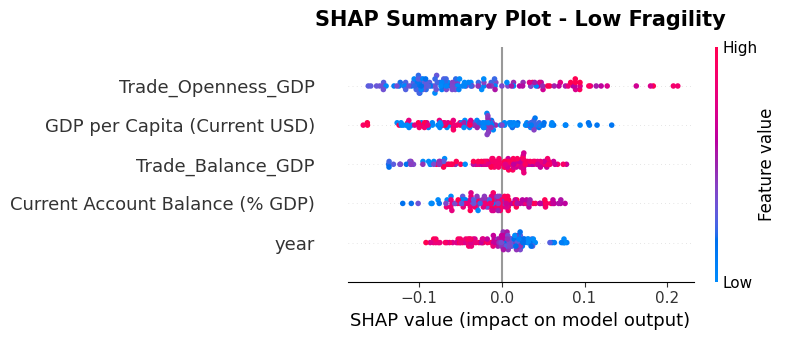

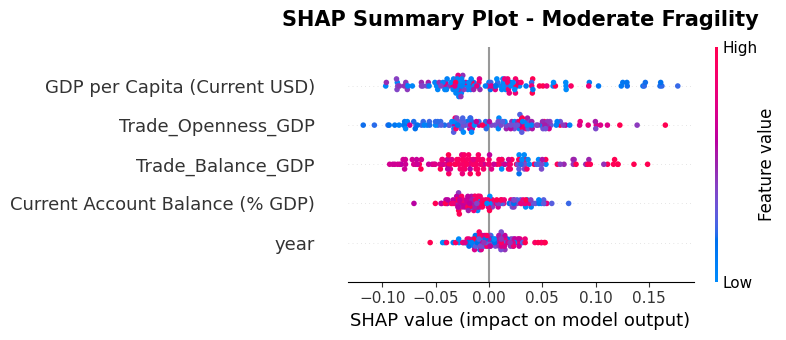

In [ ]:
import shap
import numpy as np
import matplotlib.pyplot as plt
class_names = rf_model.classes_
if isinstance(shap_values, list):
    class_shap_values = shap_values

else:
    values = np.asarray(shap_values)

    if values.ndim == 3:
        if values.shape[0] == len(X_test):
            class_shap_values = [
                values[:, :, i]
                for i in range(values.shape[2])
            ]
        else:
            class_shap_values = [
                values[i]
                for i in range(values.shape[0])
            ]

    else:
        class_shap_values = [values]
for i, class_name in enumerate(class_names):

    plt.figure(figsize=(11, 6))

    shap.summary_plot(
        class_shap_values[i],
        X_test,
        plot_type="dot",
        max_display=5,
        show=False
    )

    plt.title(
        f"SHAP Summary Plot - {class_name}",
        fontsize=15,
        fontweight="bold",
        pad=15
    )

    plt.tight_layout()
    plt.savefig(
        f"SHAP_Summary_{class_name.replace(' ', '_')}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


PREDICTED FRAGILITY CATEGORY: Low Fragility

INPUT ECONOMIC INDICATORS:


,Trade_Openness_GDP,Trade_Balance_GDP,Current Account Balance (% GDP),GDP per Capita (Current USD),year
47,53.363936,-20.497329,-10.200176,4247.631343,2012


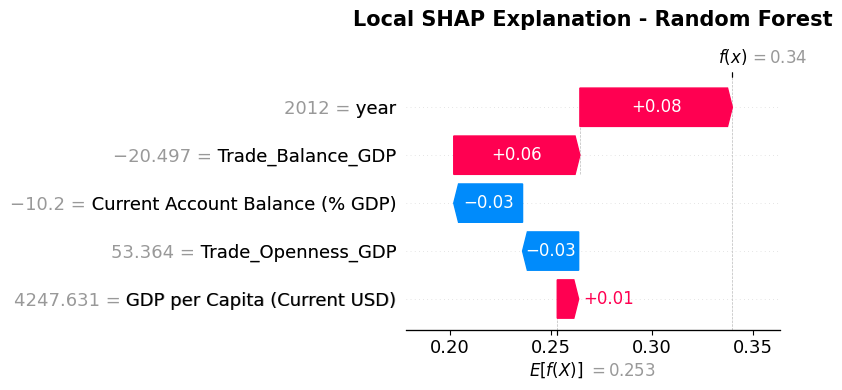

In [ ]:
import shap
import numpy as np
import matplotlib.pyplot as plt
sample = X_test.iloc[[0]]
prediction = rf_model.predict(sample)[0]

class_index = list(rf_model.classes_).index(prediction)
local_explanation = explainer(sample)
values = local_explanation.values[0, :, class_index]

base_value = local_explanation.base_values[0, class_index]

waterfall_data = shap.Explanation(
    values=values,
    base_values=base_value,
    data=sample.iloc[0].values,
    feature_names=X_test.columns.tolist()
)

print("PREDICTED FRAGILITY CATEGORY:", prediction)
print("\nINPUT ECONOMIC INDICATORS:")
display(sample)

plt.figure(figsize=(11, 7))

shap.plots.waterfall(
    waterfall_data,
    max_display=5,
    show=False
)

plt.title(
    "Local SHAP Explanation - Random Forest",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.tight_layout()

plt.savefig(
    "Figure_7_3_Local_SHAP_Explanation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


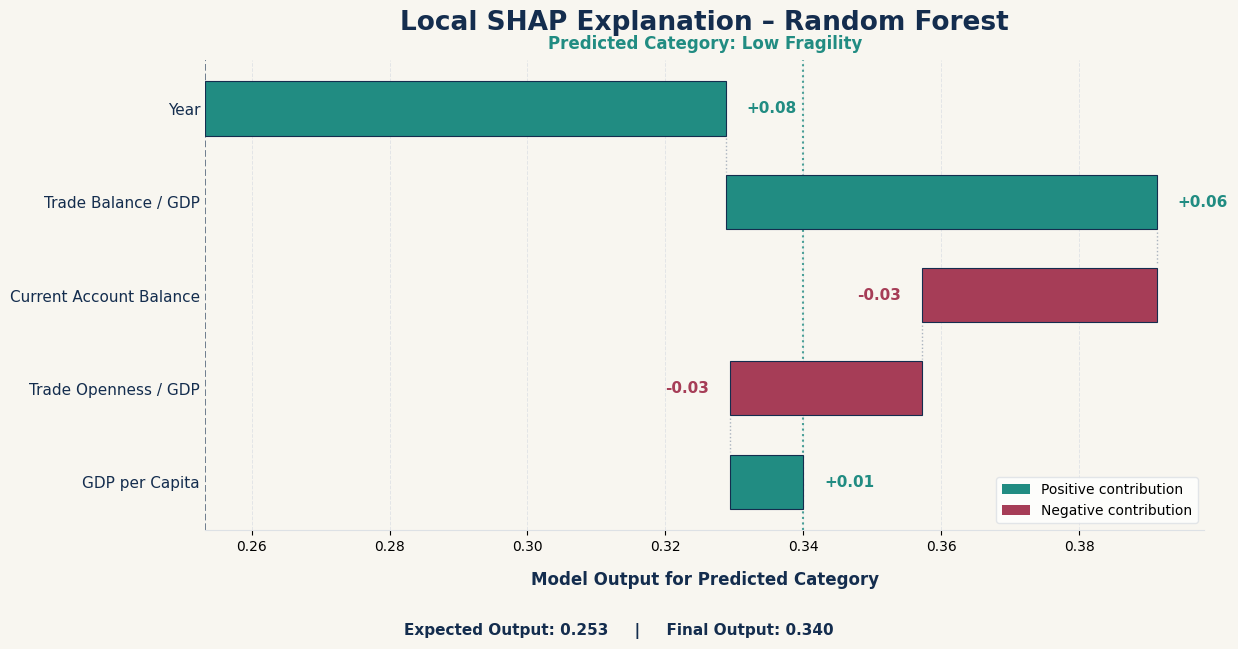

In [ ]:

import shap
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
sample = X_test.iloc[[0]]

prediction = rf_model.predict(sample)[0]

class_index = list(rf_model.classes_).index(prediction)

explainer = shap.TreeExplainer(rf_model)
explanation = explainer(sample)

raw_values = np.asarray(explanation.values)

if raw_values.ndim == 3:
    contributions = raw_values[0, :, class_index]
else:
    contributions = raw_values[0]

base_values = np.asarray(explanation.base_values)

if base_values.ndim == 2:
    base_value = float(base_values[0, class_index])
elif base_values.ndim == 1:
    base_value = float(
        base_values[class_index]
        if len(base_values) > 1
        else base_values[0]
    )
else:
    base_value = float(base_values)

feature_names = [
    "Trade Openness / GDP",
    "Trade Balance / GDP",
    "Current Account Balance",
    "GDP per Capita",
    "Year"
]

order = np.argsort(np.abs(contributions))[::-1]

contributions = contributions[order]
feature_names = [feature_names[i] for i in order]

NAVY = "#142D4E"
TEAL = "#218C82"
BURGUNDY = "#A63D57"
IVORY = "#F8F6F0"
GRID = "#DDE1E5"
final_value = base_value + contributions.sum()

cumulative = base_value
steps = []

for value in contributions:

    next_value = cumulative + value

    steps.append((cumulative, next_value, value))

    cumulative = next_value

fig, ax = plt.subplots(figsize=(13, 7))

fig.patch.set_facecolor(IVORY)
ax.set_facecolor(IVORY)

y_positions = np.arange(len(feature_names))[::-1]

for i, (start, end, value) in enumerate(steps):

    color = TEAL if value >= 0 else BURGUNDY

    ax.barh(
        y_positions[i],
        abs(value),
        left=min(start, end),
        height=0.58,
        color=color,
        edgecolor=NAVY,
        linewidth=0.8,
        zorder=3
    )
    offset = (max(final_value, base_value) -
              min(final_value, base_value)) * 0.035

    if value >= 0:
        ax.text(
            end + offset,
            y_positions[i],
            f"+{value:.2f}",
            va="center",
            ha="left",
            color=TEAL,
            fontsize=11,
            fontweight="bold"
        )

    else:
        ax.text(
            end - offset,
            y_positions[i],
            f"{value:.2f}",
            va="center",
            ha="right",
            color=BURGUNDY,
            fontsize=11,
            fontweight="bold"
        )

    if i < len(steps) - 1:
        ax.plot(
            [end, end],
            [y_positions[i] - 0.32,
             y_positions[i] - 0.68],
            color="#AAB3BE",
            linestyle=":",
            linewidth=1
        )
ax.set_yticks(y_positions)
ax.set_yticklabels(
    feature_names,
    fontsize=11,
    fontweight="medium",
    color=NAVY
)
ax.axvline(
    base_value,
    color=NAVY,
    linestyle="--",
    linewidth=1.3,
    alpha=0.65
)

ax.axvline(
    final_value,
    color=TEAL,
    linestyle=":",
    linewidth=1.5,
    alpha=0.8
)

# 13. Titles
ax.set_title(
    "Local SHAP Explanation – Random Forest",
    fontsize=19,
    fontweight="bold",
    color=NAVY,
    pad=22
)

ax.text(
    0.5,
    1.025,
    f"Predicted Category: {prediction}",
    transform=ax.transAxes,
    ha="center",
    fontsize=12,
    color=TEAL,
    fontweight="bold"
)

ax.set_xlabel(
    "Model Output for Predicted Category",
    fontsize=12,
    fontweight="bold",
    color=NAVY,
    labelpad=12
)

# 14. Grid and formatting
ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.7,
    color=GRID,
    alpha=0.8
)

ax.tick_params(axis="x", labelsize=10)
ax.tick_params(axis="y", length=0)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.spines["bottom"].set_color(GRID)

# 15. Legend
legend_elements = [
    Patch(
        facecolor=TEAL,
        label="Positive contribution"
    ),
    Patch(
        facecolor=BURGUNDY,
        label="Negative contribution"
    )
]

ax.legend(
    handles=legend_elements,
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor=GRID,
    fontsize=10
)

# 16. Expected and final output
fig.text(
    0.5,
    0.025,
    f"Expected Output: {base_value:.3f}     |     "
    f"Final Output: {final_value:.3f}",
    ha="center",
    fontsize=11,
    color=NAVY,
    fontweight="bold"
)

plt.tight_layout(rect=[0.02, 0.07, 0.98, 0.94])

plt.savefig(
    "Figure_7_3_Local_SHAP_Premium_Design.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()
